In [1]:
import pandas as pd
from config import RESSERENO_ROOT
from bfmn_building import pipeline_multiple_participants

In [2]:
demographics_2024 = pd.read_csv(
    "/Users/emma/projects/cognoscolab/rassereno/out/formatting/psychology_BA_2024/all_questionnaires_task_2024.csv"
)
female_participants_2024 = demographics_2024["participant_id"][
    demographics_2024["gender"] == "Femminile"
]
male_participants_2024 = demographics_2024["participant_id"][
    demographics_2024["gender"] == "Maschile"
]
print(
    "2024 \nFemale participants:",
    len(female_participants_2024),
    "\nMale participants:",
    len(male_participants_2024),
)

2024 
Female participants: 120 
Male participants: 43


In [3]:
demographics_2025 = pd.read_csv(
    "/Users/emma/projects/cognoscolab/rassereno/out/formatting/all_students_2025/all_questionnaires_2025.csv"
)
demographics_2025 = demographics_2025[~demographics_2025["gender"].isna()]
female_participants_2025 = demographics_2025["participant_id"][
    demographics_2025["gender"] == "F"
]
male_participants_2025 = demographics_2025["participant_id"][
    demographics_2025["gender"] == "M"
]
print(
    "2025 \nFemale participants:",
    len(female_participants_2025),
    "\nMale participants:",
    len(male_participants_2025),
)

2025 
Female participants: 52 
Male participants: 26


## Data trimming

In [35]:
associations_valence_2024 = pd.read_csv(
    "/Users/emma/projects/cognoscolab/rassereno/out/formatting/psychology_BA_2024/associations_valence_2024.csv"
)
data_female_2024 = associations_valence_2024[
    associations_valence_2024["participant_id"].isin(female_participants_2024)
]
data_male_2024 = associations_valence_2024[
    associations_valence_2024["participant_id"].isin(male_participants_2024)
]
print("female psychologists:", len(data_female_2024["participant_id"].unique()))
print("male psychologists:", len(data_male_2024["participant_id"].unique()))

female psychologists: 120
male psychologists: 43


In [6]:
associations_valence_2025 = pd.read_csv(
    "/Users/emma/projects/cognoscolab/rassereno/out/formatting/all_students_2025/associations_valence_task_2025.csv"
)
data_female_2025 = associations_valence_2025[
    associations_valence_2025["participant_id"].isin(female_participants_2025)
]
data_male_2025 = associations_valence_2025[
    associations_valence_2025["participant_id"].isin(male_participants_2025)
]

In [17]:
liceo_data = associations_valence_2025[
    associations_valence_2025["participant_id"].str.startswith("liceo")
]
fisica_data = associations_valence_2025[
    associations_valence_2025["participant_id"].str.startswith("fisica")
]
len(fisica_data["participant_id"].unique())

18

In [25]:
females_2025_liceo = data_female_2025[
    data_female_2025["participant_id"].str.startswith("liceo")
]
males_2025_liceo = data_male_2025[
    data_male_2025["participant_id"].str.startswith("liceo")
]
print(
    "females in scienze applicate:",
    len(
        females_2025_liceo["participant_id"][
            females_2025_liceo["participant_id"].str.startswith("liceo_sci")
        ].unique()
    ),
)
print(
    "males in scienze applicate:",
    len(
        males_2025_liceo["participant_id"][
            males_2025_liceo["participant_id"].str.startswith("liceo_sci")
        ].unique()
    ),
)
print(
    "total scienze applicate",
    len(
        liceo_data["participant_id"][
            liceo_data["participant_id"].str.startswith("liceo_sci")
        ].unique()
    ),
)

females in scienze applicate: 24
males in scienze applicate: 18
total scienze applicate 42


In [26]:
print(
    "females in linguistico:",
    len(
        females_2025_liceo["participant_id"][
            females_2025_liceo["participant_id"].str.startswith("liceo_lin")
        ].unique()
    ),
)
print(
    "males in linguistico:",
    len(
        males_2025_liceo["participant_id"][
            males_2025_liceo["participant_id"].str.startswith("liceo_lin")
        ].unique()
    ),
)
print(
    "total linguistico",
    len(
        liceo_data["participant_id"][
            liceo_data["participant_id"].str.startswith("liceo_lin")
        ].unique()
    ),
)

females in linguistico: 16
males in linguistico: 2
total linguistico 18


In [32]:
mask = ~liceo_data["participant_id"].str.startswith("liceo_lin") & ~liceo_data[
    "participant_id"
].str.startswith("liceo_sci")

print("total", liceo_data[mask])

total      participant_id    cue_word  valence_cue_word association_1  \
92        liceo_063     scienza               4.0        metodo   
93        liceo_064     scienza               4.0       pesante   
195       liceo_063  statistica               4.0  popolazione    
196       liceo_064  statistica               4.0          noia   
298       liceo_063     ipotesi               4.0      premessa   
...             ...         ...               ...           ...   
4110      liceo_064       esame               2.0         guida   
4212      liceo_063      futuro               4.0   incertezza    
4213      liceo_064      futuro               3.0       radioso   
4315      liceo_063        vita               4.0         bello   
4316      liceo_064        vita               4.0       vissuta   

      valence_association_1  association_2  valence_association_2  \
92                      4.0  epistemologia                    4.0   
93                      4.0     importante         

In [8]:
fisica_female = data_female_2025[
    data_female_2025["participant_id"].str.startswith("fisica")
]
fisica_male = data_male_2025[data_male_2025["participant_id"].str.startswith("fisica")]

## BFMN

In [9]:
keywords = ["ansia", "matematica", "fisica", "esame", "scienza"]

Number of unique words: 1254


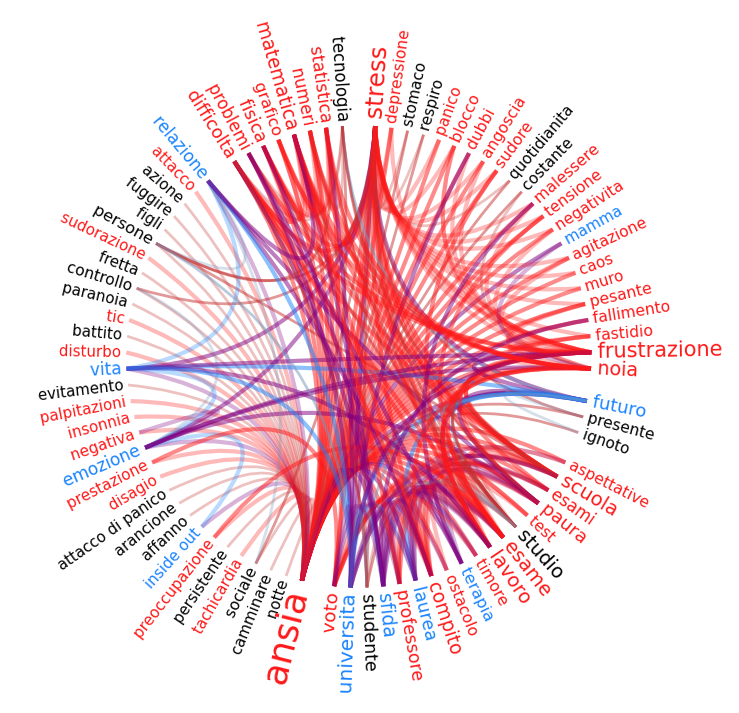

Local clustering ansia: 0.06200411401704378
Degree ansia: 83
Counts of 'ansia' = {'positive': 10, 'negative': 49, 'neutral': 25}
Mode of 'ansia' = negative


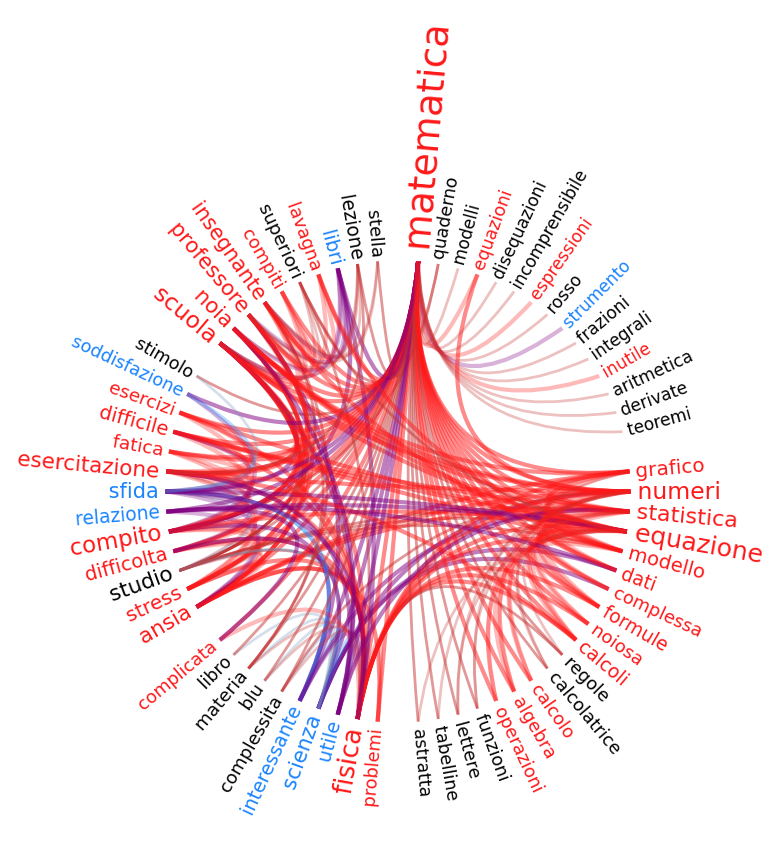

Local clustering matematica: 0.08717948717948718
Degree matematica: 66
Counts of 'matematica' = {'positive': 8, 'negative': 34, 'neutral': 25}
Mode of 'matematica' = negative


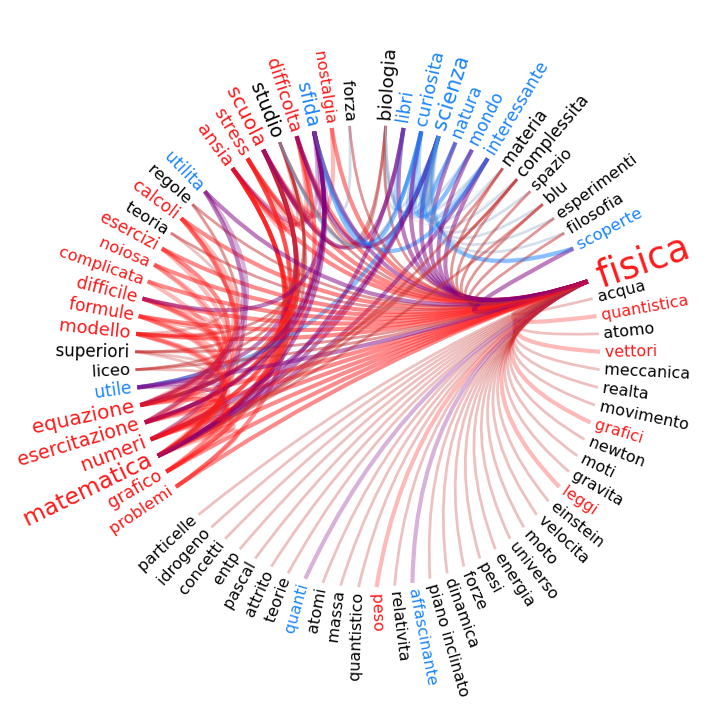

Local clustering fisica: 0.04105263157894737
Degree fisica: 76
Counts of 'fisica' = {'positive': 12, 'negative': 24, 'neutral': 41}
Mode of 'fisica' = neutral


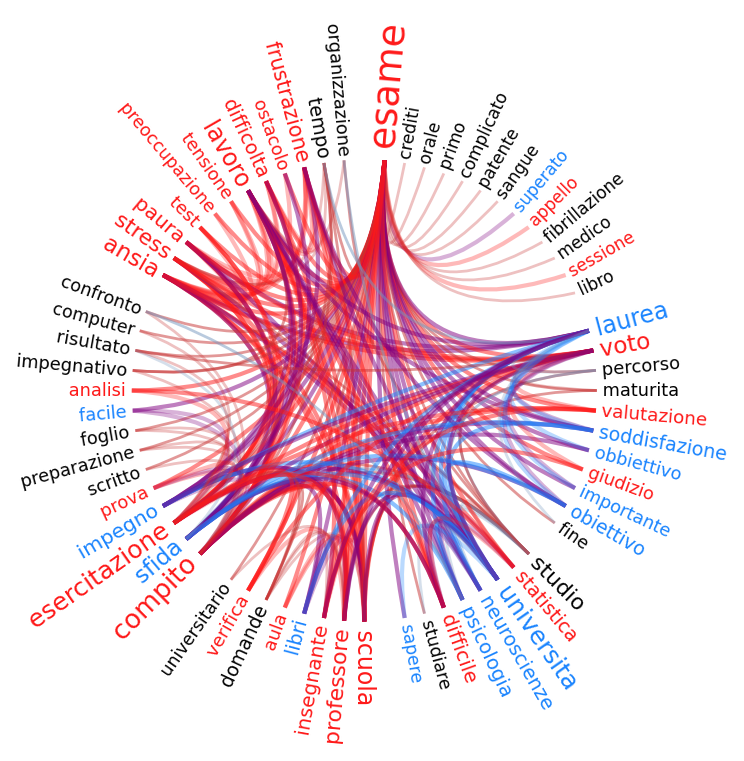

Local clustering esame: 0.09519230769230769
Degree esame: 65
Counts of 'esame' = {'positive': 14, 'negative': 27, 'neutral': 25}
Mode of 'esame' = negative


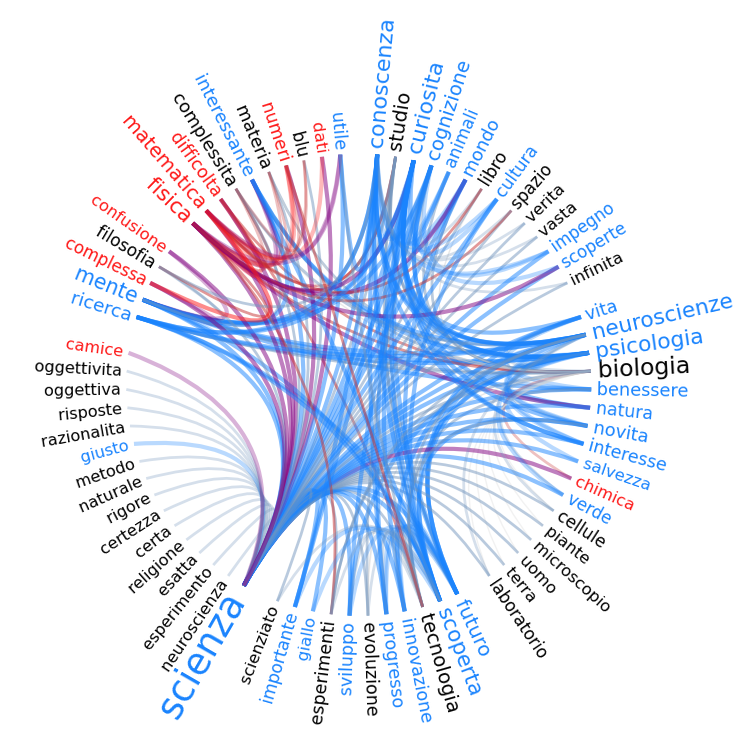

Local clustering scienza: 0.06768388106416276
Degree scienza: 72
Counts of 'scienza' = {'positive': 30, 'negative': 9, 'neutral': 34}
Mode of 'scienza' = neutral


In [10]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=associations_valence_2024,
    keywords=keywords,
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/all_psychology",
    flower="no",
    filtering="yes",
)

Number of unique words: 1961


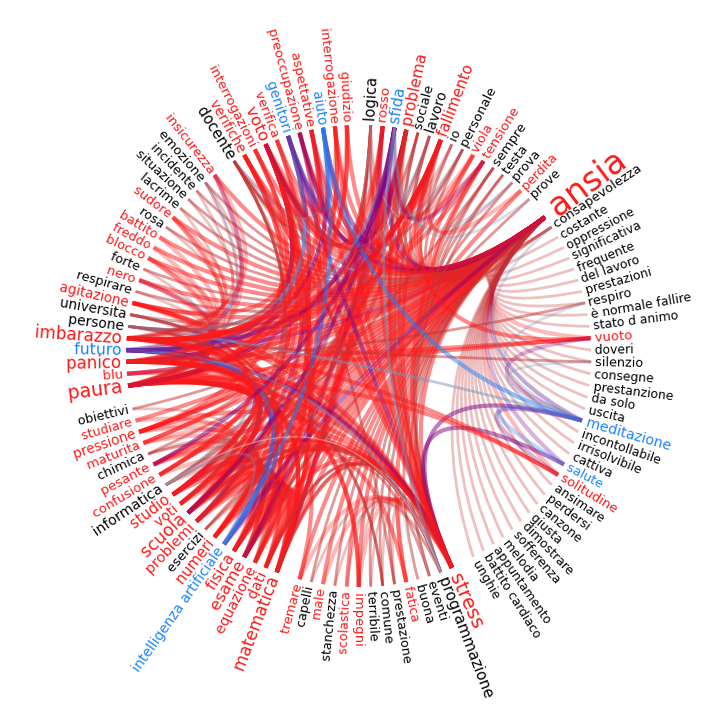

Local clustering ansia: 0.04683447749809306
Degree ansia: 115
Counts of 'ansia' = {'positive': 7, 'negative': 49, 'neutral': 60}
Mode of 'ansia' = neutral


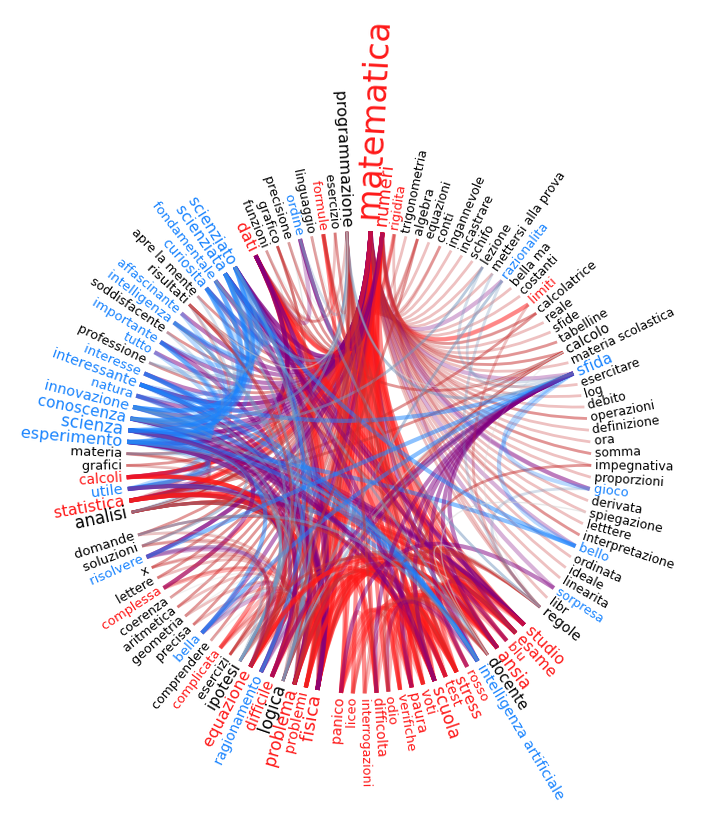

Local clustering matematica: 0.05496610669024462
Degree matematica: 117
Counts of 'matematica' = {'positive': 26, 'negative': 31, 'neutral': 61}
Mode of 'matematica' = neutral


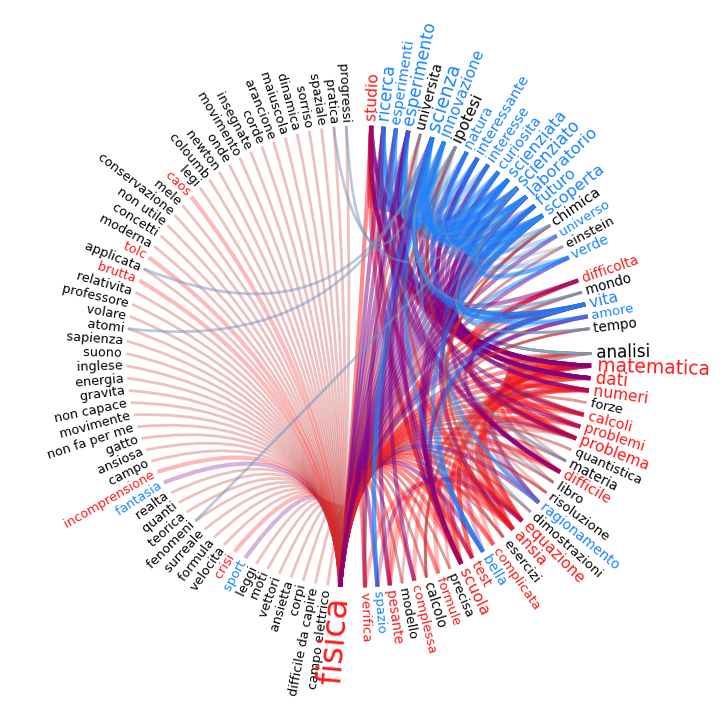

Local clustering fisica: 0.04247104247104247
Degree fisica: 112
Counts of 'fisica' = {'positive': 23, 'negative': 24, 'neutral': 66}
Mode of 'fisica' = neutral


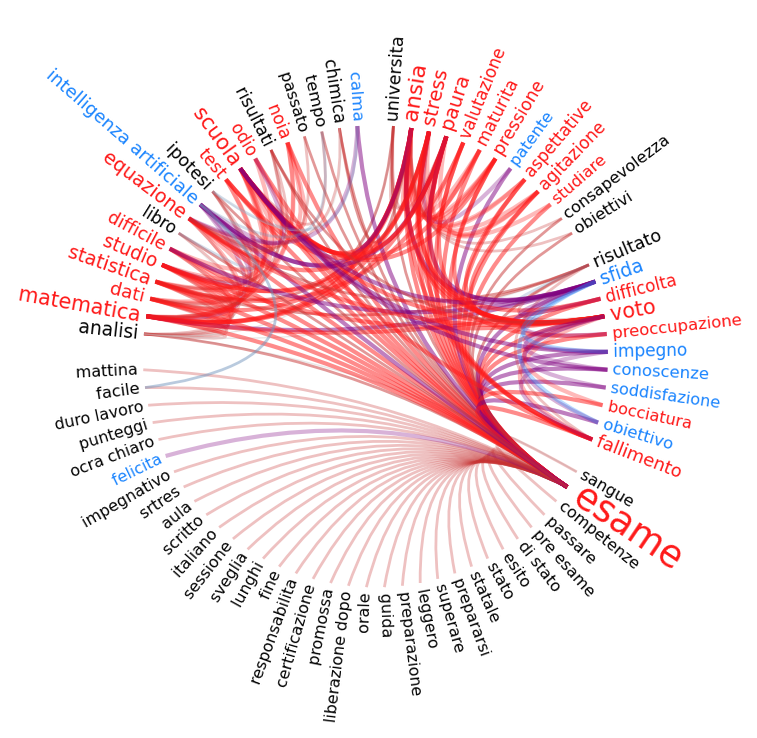

Local clustering esame: 0.04666666666666667
Degree esame: 76
Counts of 'esame' = {'positive': 9, 'negative': 25, 'neutral': 43}
Mode of 'esame' = neutral


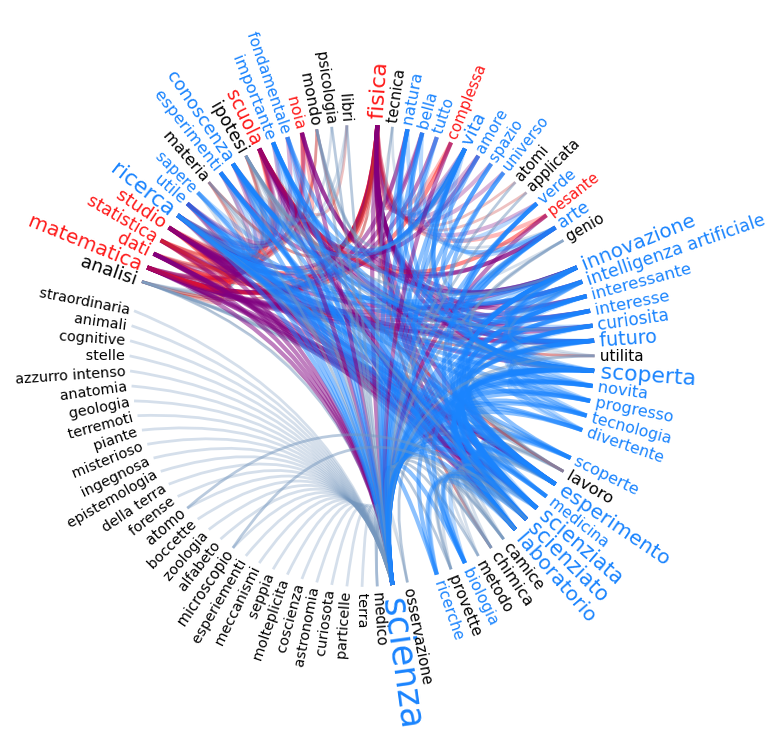

Local clustering scienza: 0.07690387016229713
Degree scienza: 90
Counts of 'scienza' = {'positive': 36, 'negative': 9, 'neutral': 46}
Mode of 'scienza' = neutral


In [12]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=liceo_data,
    keywords=keywords,
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/all_liceo",
    flower="no",
)

Number of unique words: 925


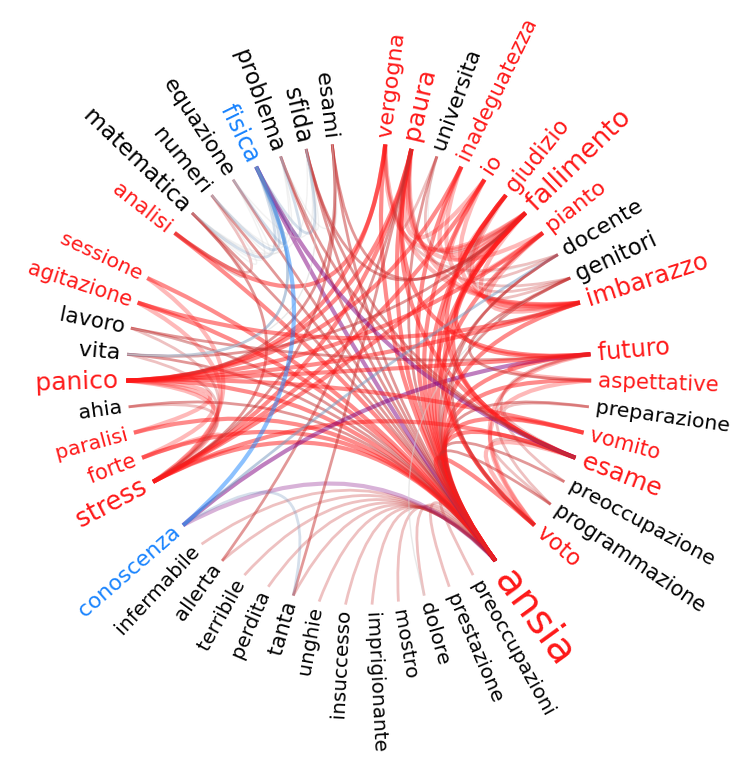

Local clustering ansia: 0.0858843537414966
Degree ansia: 49
Counts of 'ansia' = {'positive': 2, 'negative': 21, 'neutral': 27}
Mode of 'ansia' = neutral


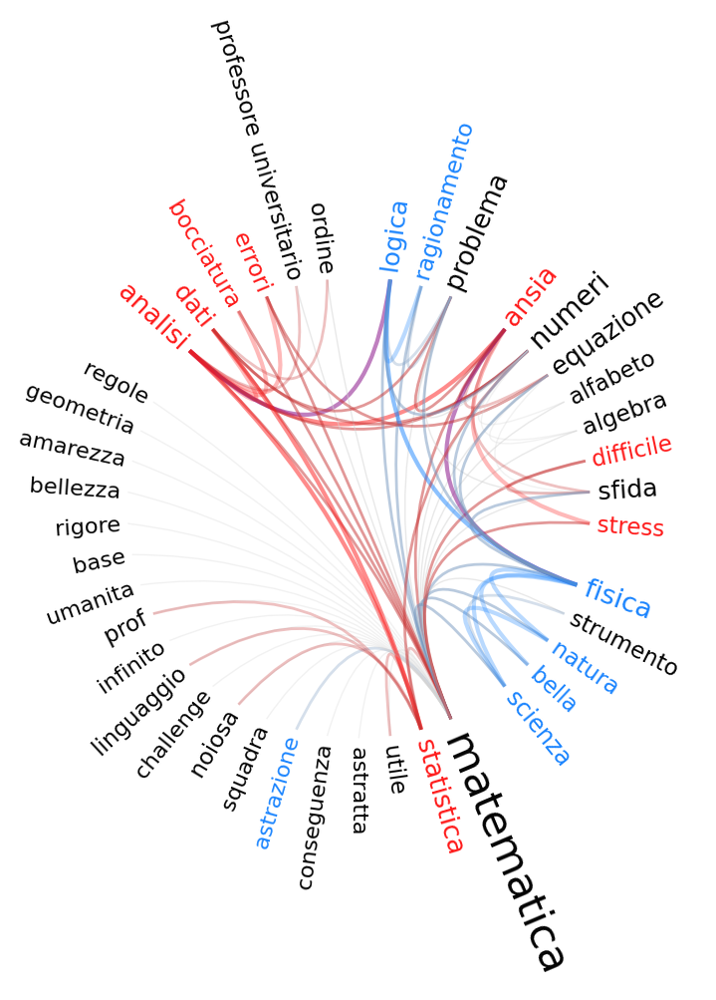

Local clustering matematica: 0.05897435897435897
Degree matematica: 40
Counts of 'matematica' = {'positive': 7, 'negative': 8, 'neutral': 26}
Mode of 'matematica' = neutral


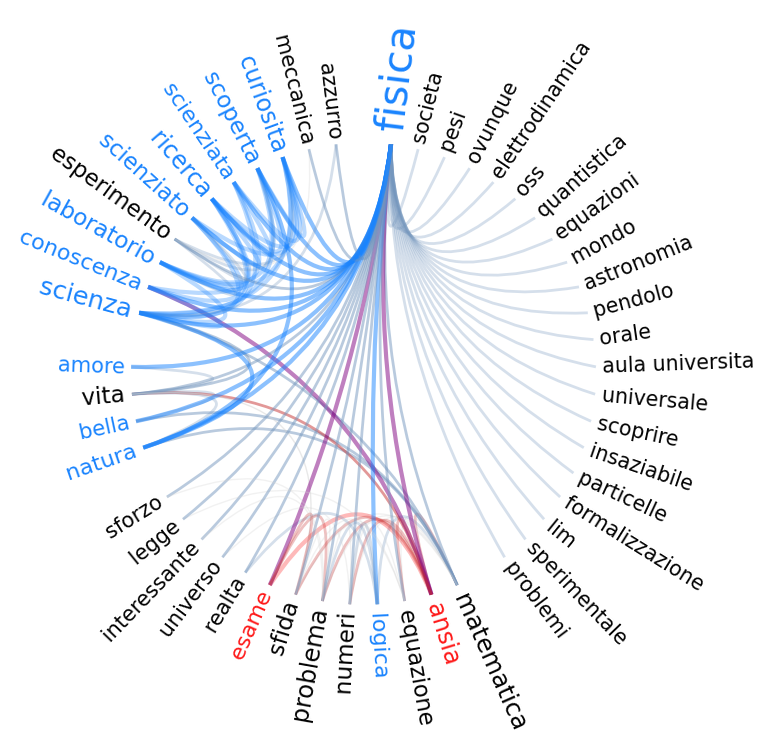

Local clustering fisica: 0.0549645390070922
Degree fisica: 48
Counts of 'fisica' = {'positive': 13, 'negative': 2, 'neutral': 34}
Mode of 'fisica' = neutral


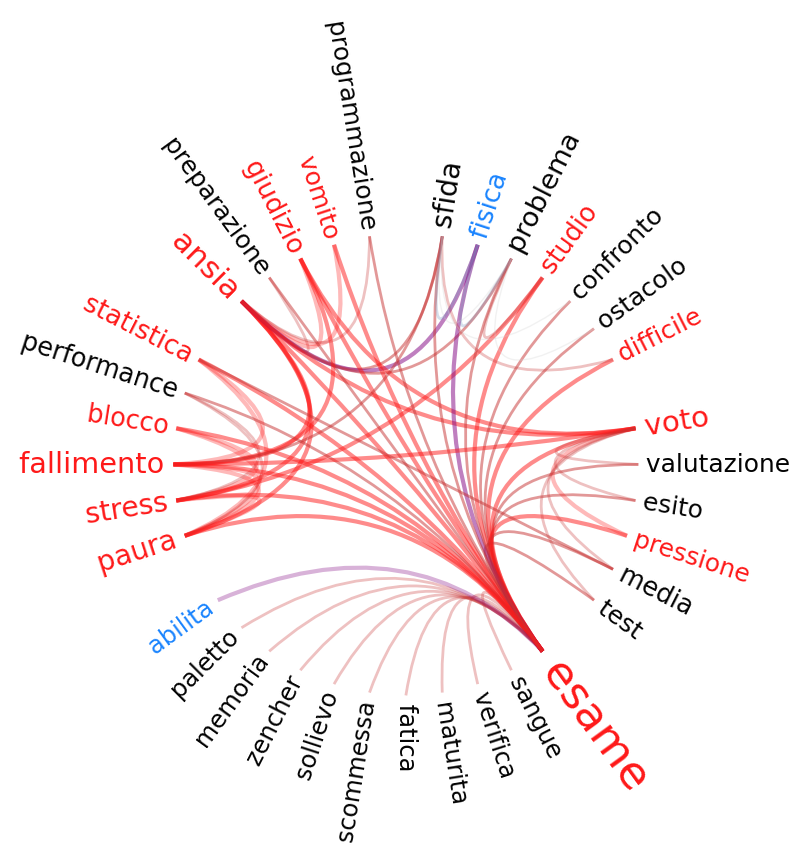

Local clustering esame: 0.0677361853832442
Degree esame: 34
Counts of 'esame' = {'positive': 2, 'negative': 13, 'neutral': 20}
Mode of 'esame' = neutral


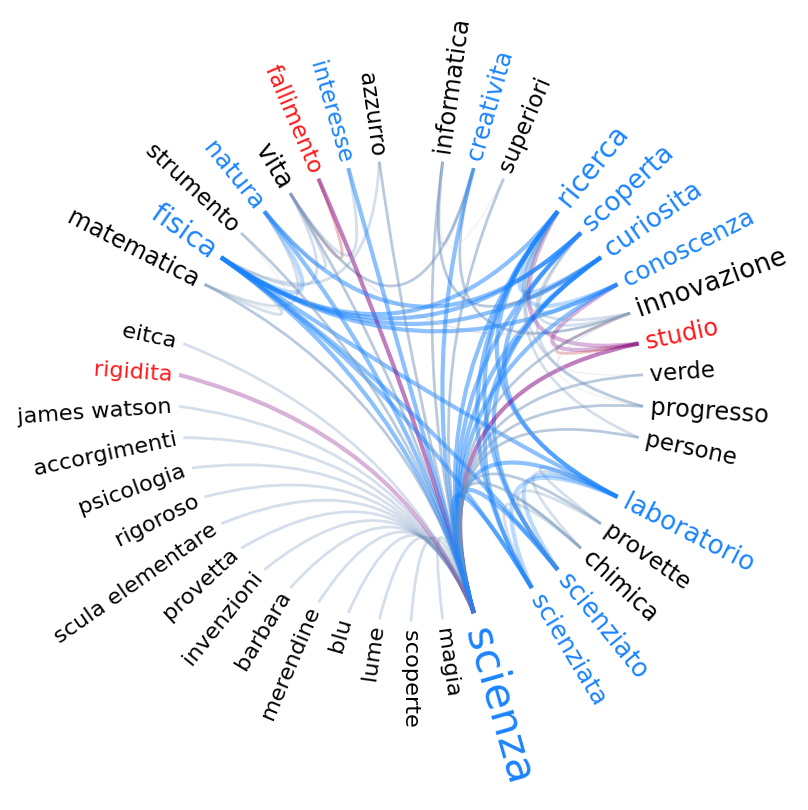

Local clustering scienza: 0.06538461538461539
Degree scienza: 40
Counts of 'scienza' = {'positive': 12, 'negative': 3, 'neutral': 26}
Mode of 'scienza' = neutral


In [14]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=fisica_data,
    keywords=keywords,
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/all_fisica",
    flower="no",
)

Number of unique words: 997


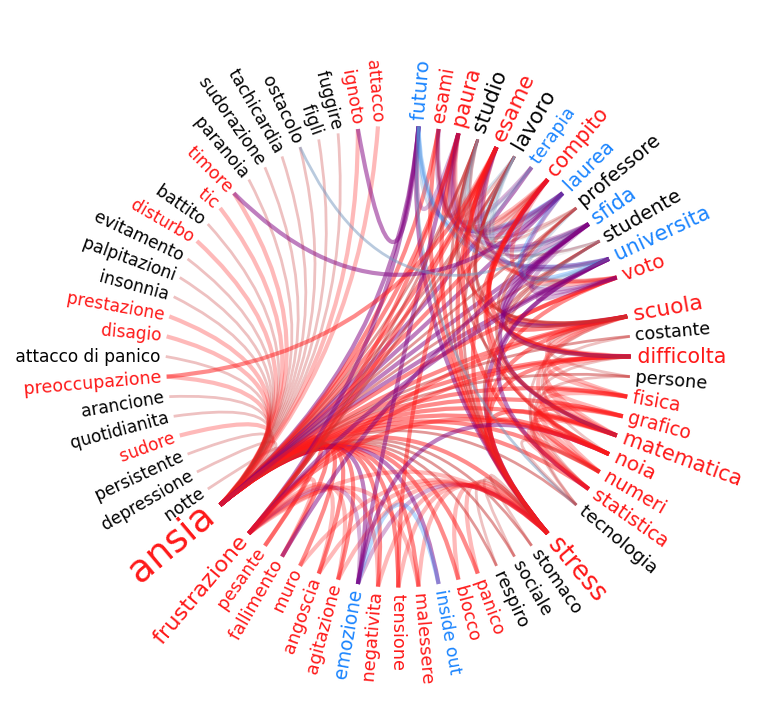

Local clustering ansia: 0.06512890094979647
Degree ansia: 67
Counts of 'ansia' = {'positive': 7, 'negative': 35, 'neutral': 26}
Mode of 'ansia' = negative


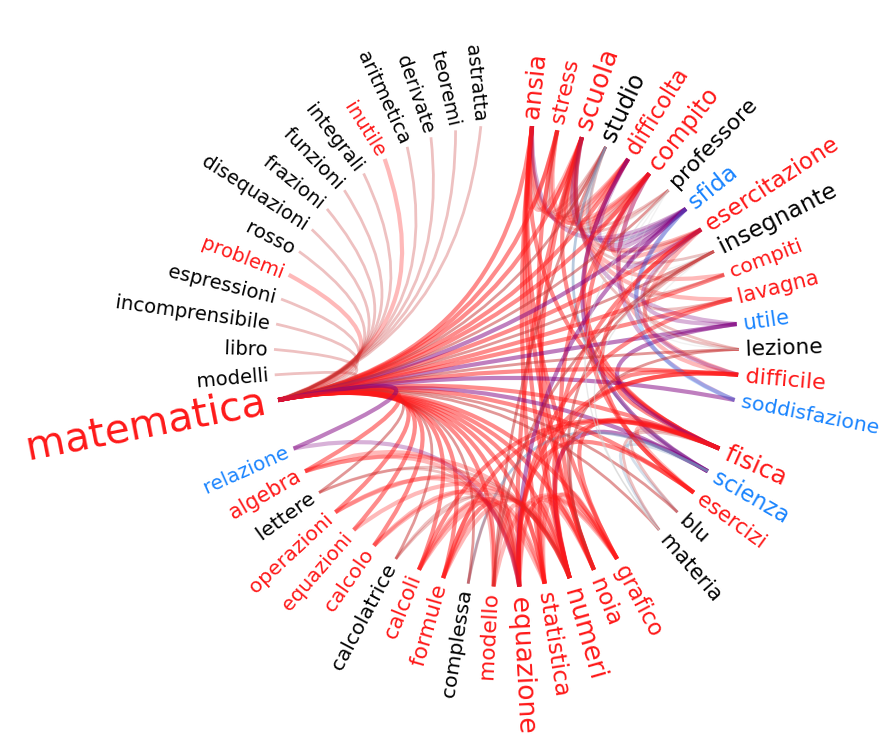

Local clustering matematica: 0.08823529411764706
Degree matematica: 52
Counts of 'matematica' = {'positive': 5, 'negative': 26, 'neutral': 22}
Mode of 'matematica' = negative


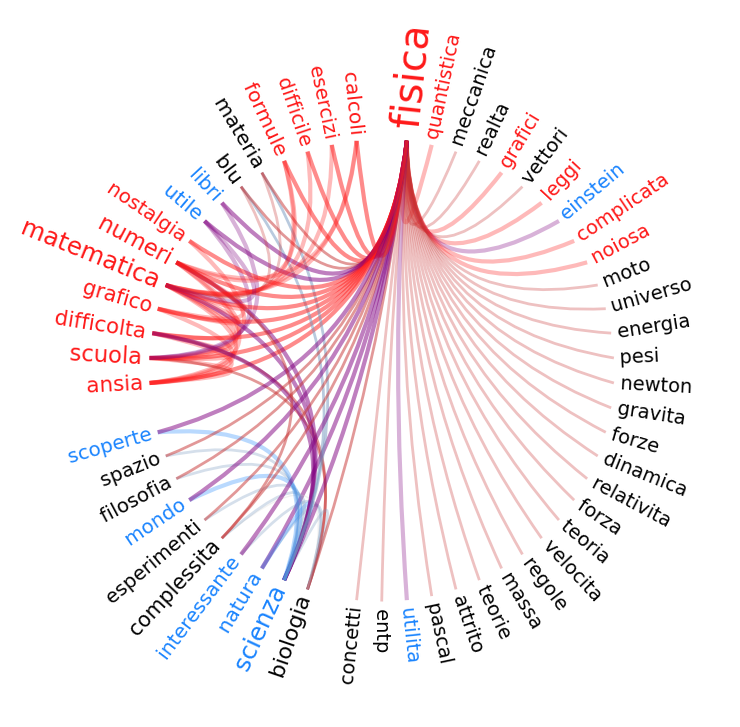

Local clustering fisica: 0.03004891684136967
Degree fisica: 54
Counts of 'fisica' = {'positive': 9, 'negative': 17, 'neutral': 29}
Mode of 'fisica' = neutral


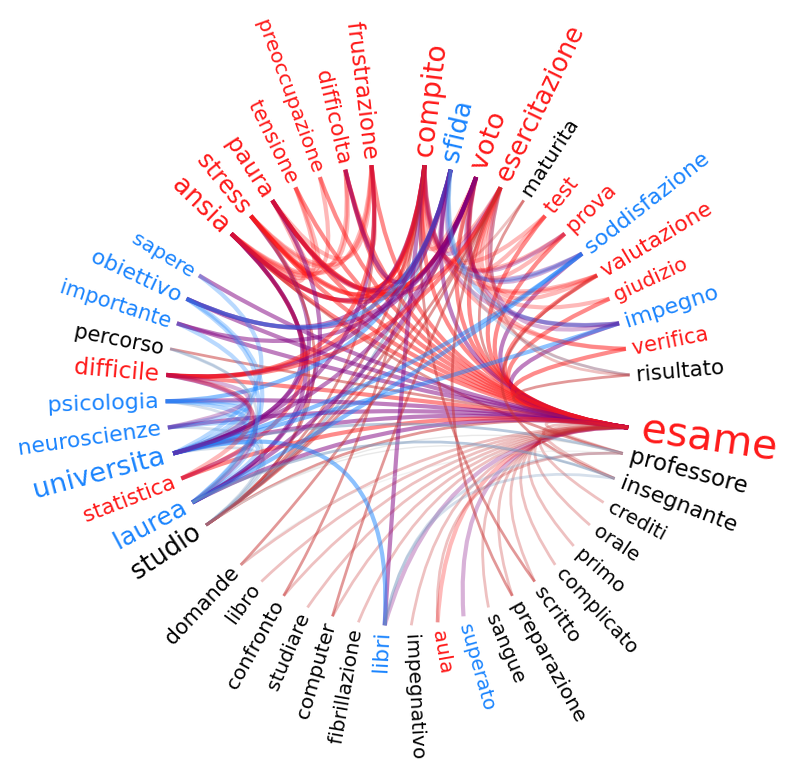

Local clustering esame: 0.09387755102040816
Degree esame: 50
Counts of 'esame' = {'positive': 12, 'negative': 19, 'neutral': 20}
Mode of 'esame' = neutral


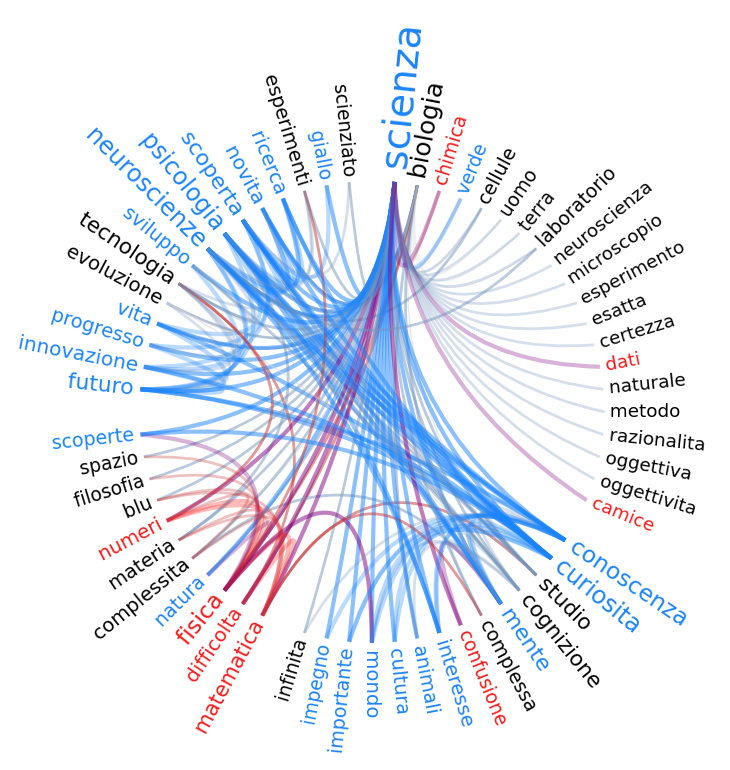

Local clustering scienza: 0.07071887784921099
Degree scienza: 59
Counts of 'scienza' = {'positive': 24, 'negative': 8, 'neutral': 28}
Mode of 'scienza' = neutral


In [33]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=data_female_2024,
    keywords=keywords,
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/psychology_females",
    flower="no",
    filtering="yes",
)

Number of unique words: 1703


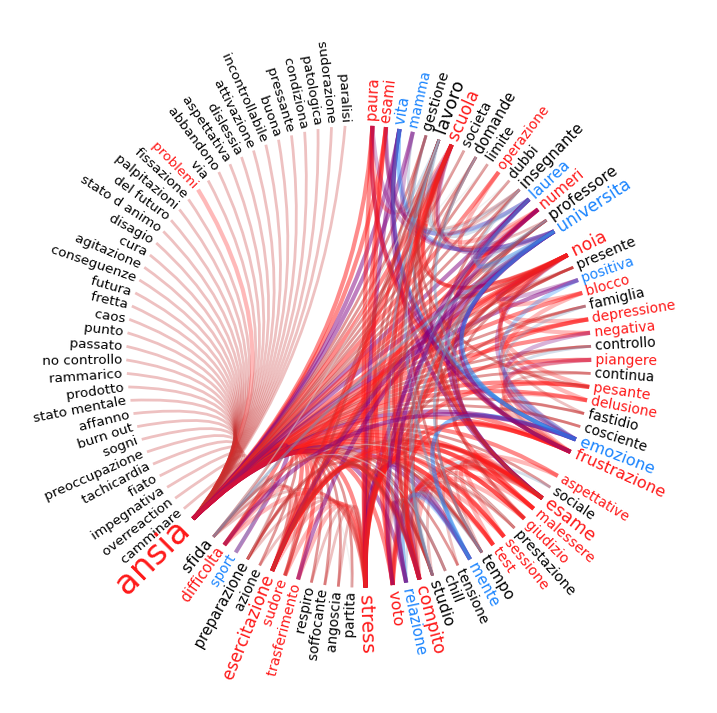

Local clustering ansia: 0.03683168316831683
Degree ansia: 101
Counts of 'ansia' = {'positive': 9, 'negative': 28, 'neutral': 65}
Mode of 'ansia' = neutral


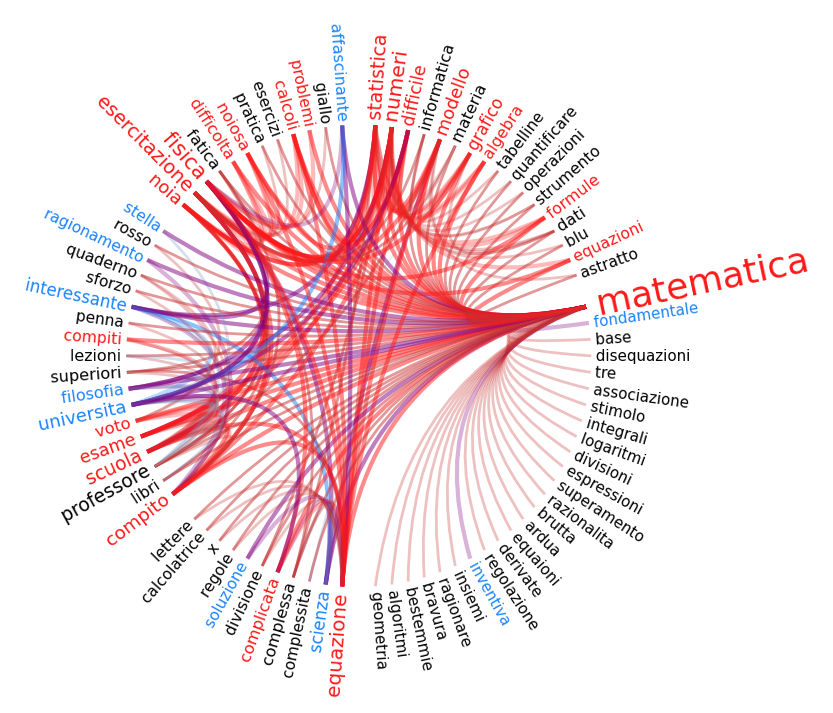

Local clustering matematica: 0.04396266184884071
Degree matematica: 82
Counts of 'matematica' = {'positive': 10, 'negative': 23, 'neutral': 50}
Mode of 'matematica' = neutral


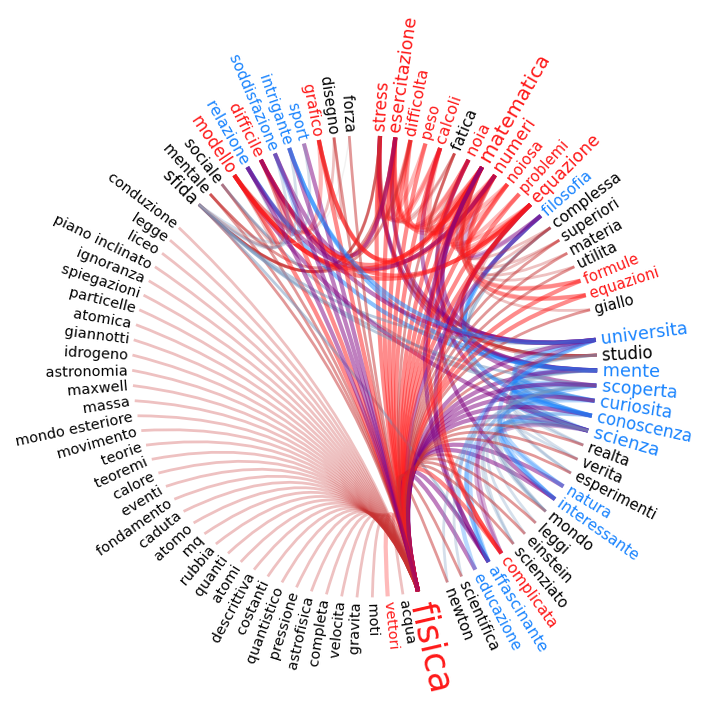

Local clustering fisica: 0.03545568039950062
Degree fisica: 90
Counts of 'fisica' = {'positive': 15, 'negative': 19, 'neutral': 57}
Mode of 'fisica' = neutral


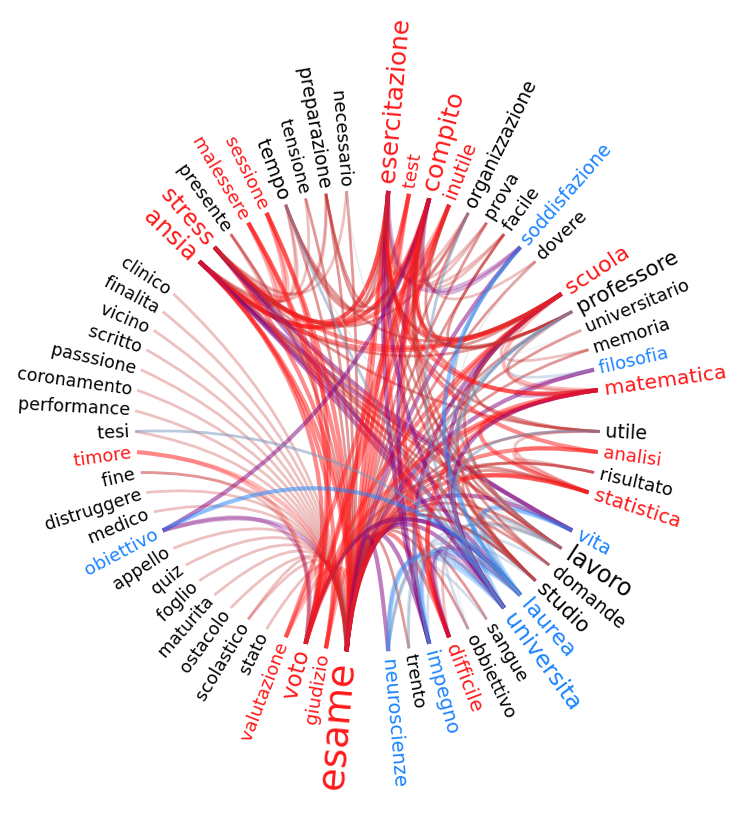

Local clustering esame: 0.07834101382488479
Degree esame: 63
Counts of 'esame' = {'positive': 8, 'negative': 18, 'neutral': 38}
Mode of 'esame' = neutral


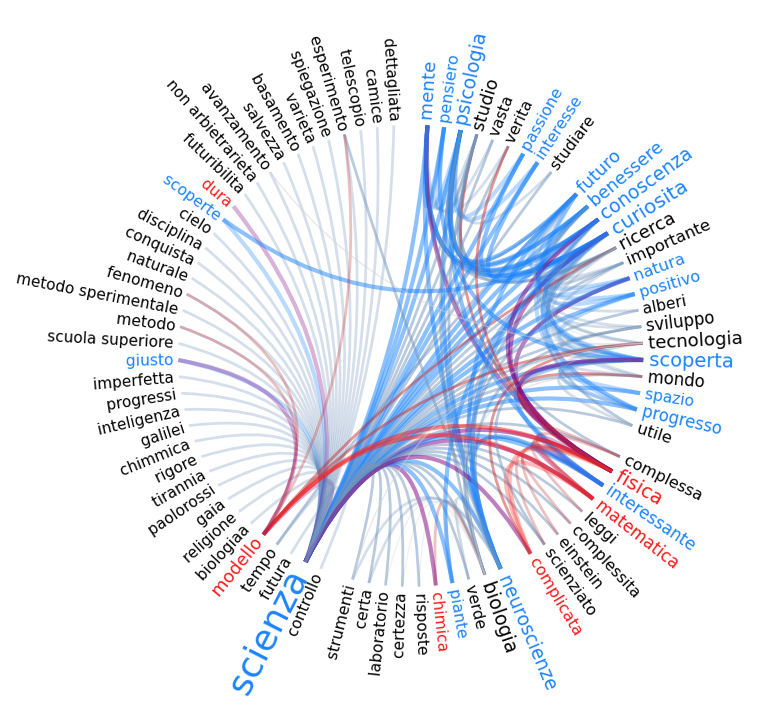

Local clustering scienza: 0.03950617283950617
Degree scienza: 81
Counts of 'scienza' = {'positive': 20, 'negative': 6, 'neutral': 56}
Mode of 'scienza' = neutral


In [ ]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=data_male_2024,
    keywords=keywords,
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/psychology_males",
    flower="no",
)

Number of unique words: 1791


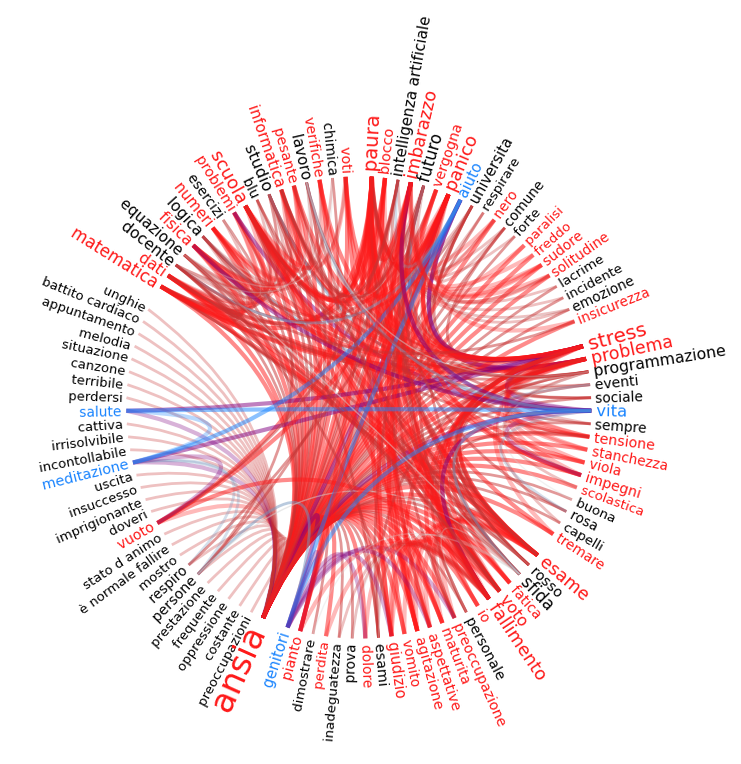

Local clustering ansia: 0.054945054945054944
Degree ansia: 105
Counts of 'ansia' = {'positive': 5, 'negative': 45, 'neutral': 56}
Mode of 'ansia' = neutral


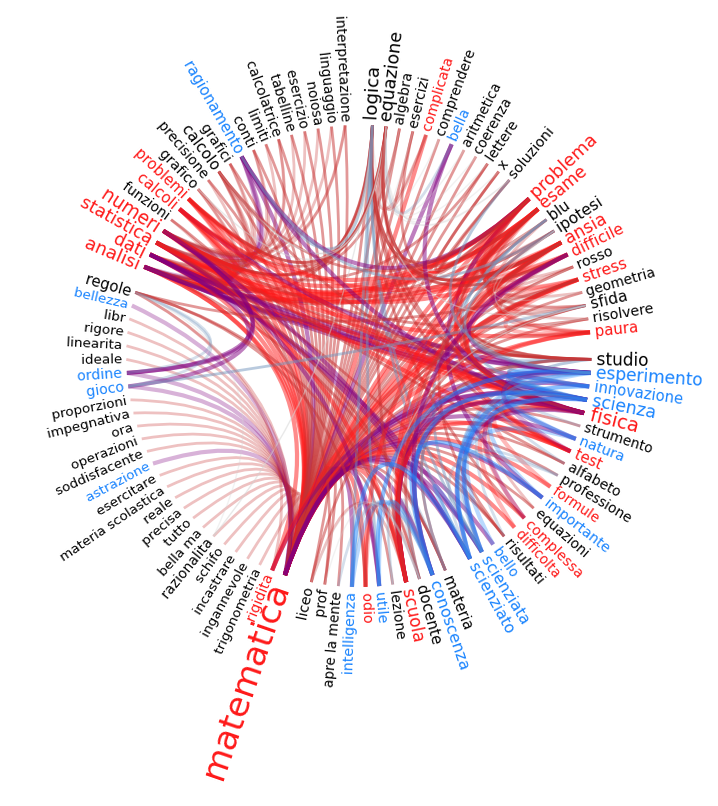

Local clustering matematica: 0.05313131313131313
Degree matematica: 100
Counts of 'matematica' = {'positive': 17, 'negative': 22, 'neutral': 62}
Mode of 'matematica' = neutral


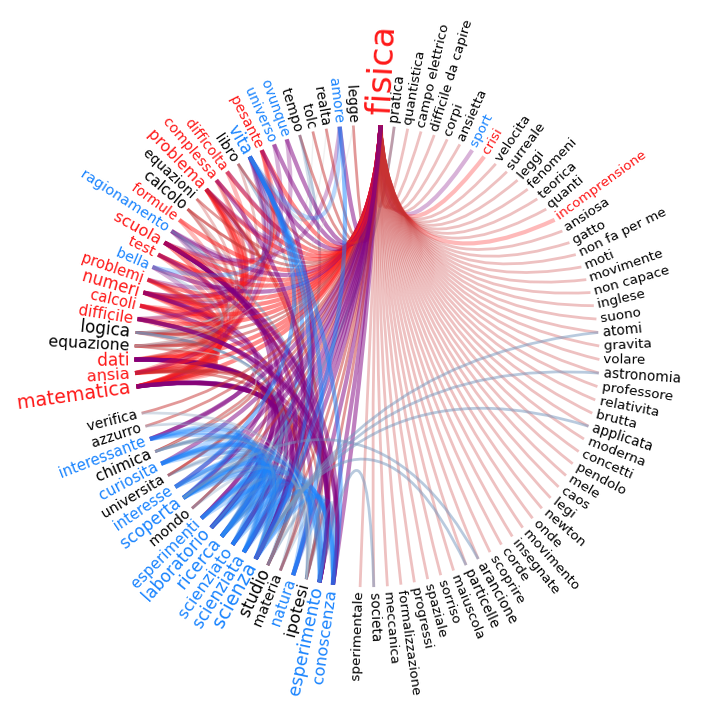

Local clustering fisica: 0.04150009518370455
Degree fisica: 103
Counts of 'fisica' = {'positive': 20, 'negative': 17, 'neutral': 67}
Mode of 'fisica' = neutral


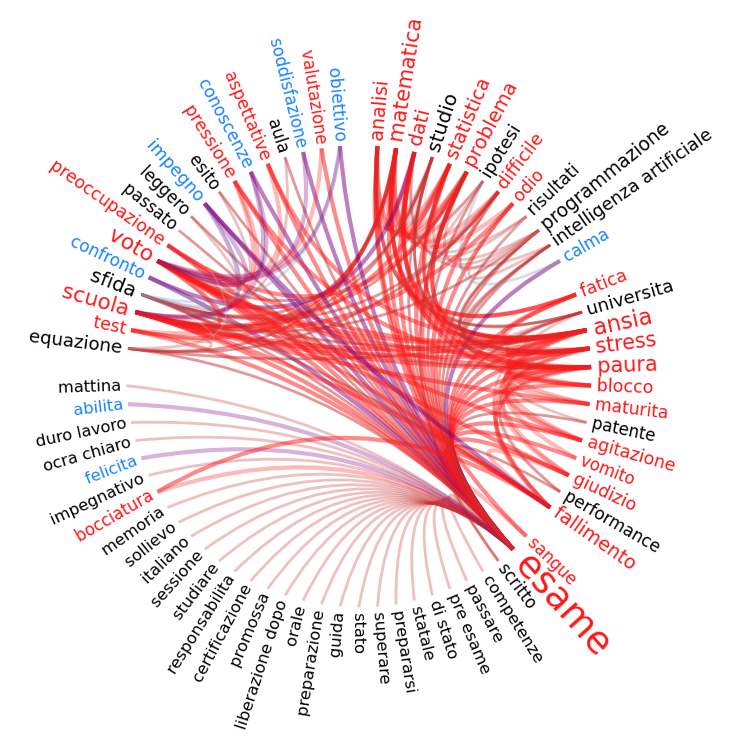

Local clustering esame: 0.05289193302891933
Degree esame: 73
Counts of 'esame' = {'positive': 8, 'negative': 27, 'neutral': 39}
Mode of 'esame' = neutral


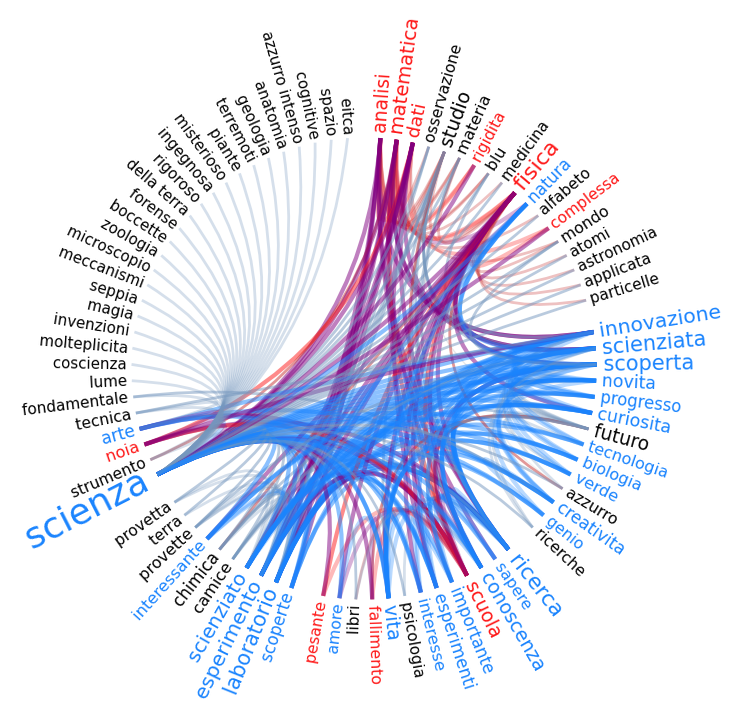

Local clustering scienza: 0.06758742286218043
Degree scienza: 83
Counts of 'scienza' = {'positive': 27, 'negative': 10, 'neutral': 47}
Mode of 'scienza' = neutral


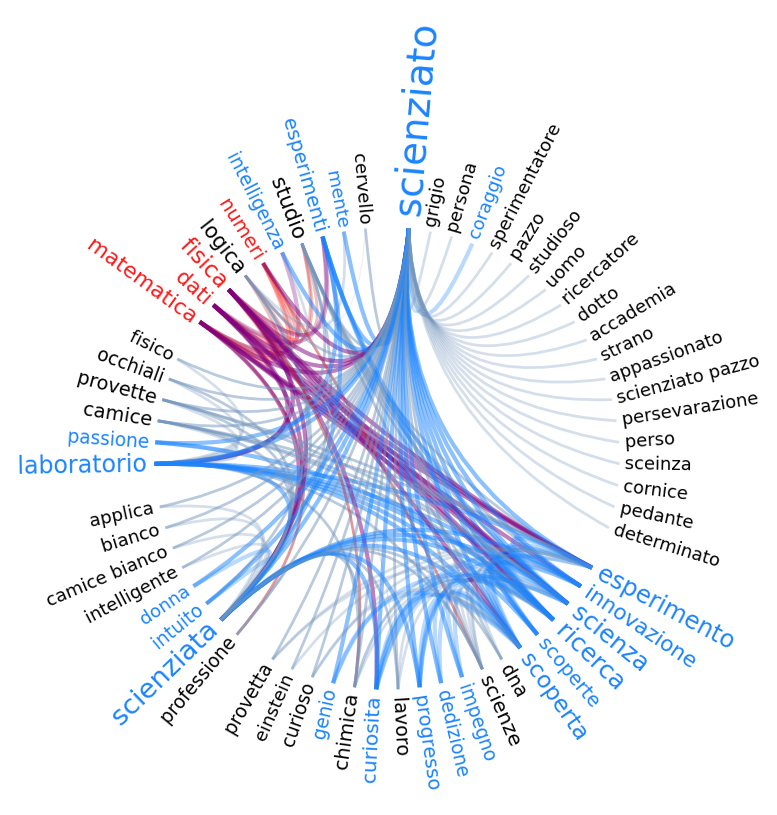

Local clustering scienziato: 0.073224043715847
Degree scienziato: 61
Counts of 'scienziato' = {'positive': 21, 'negative': 4, 'neutral': 37}
Mode of 'scienziato' = neutral


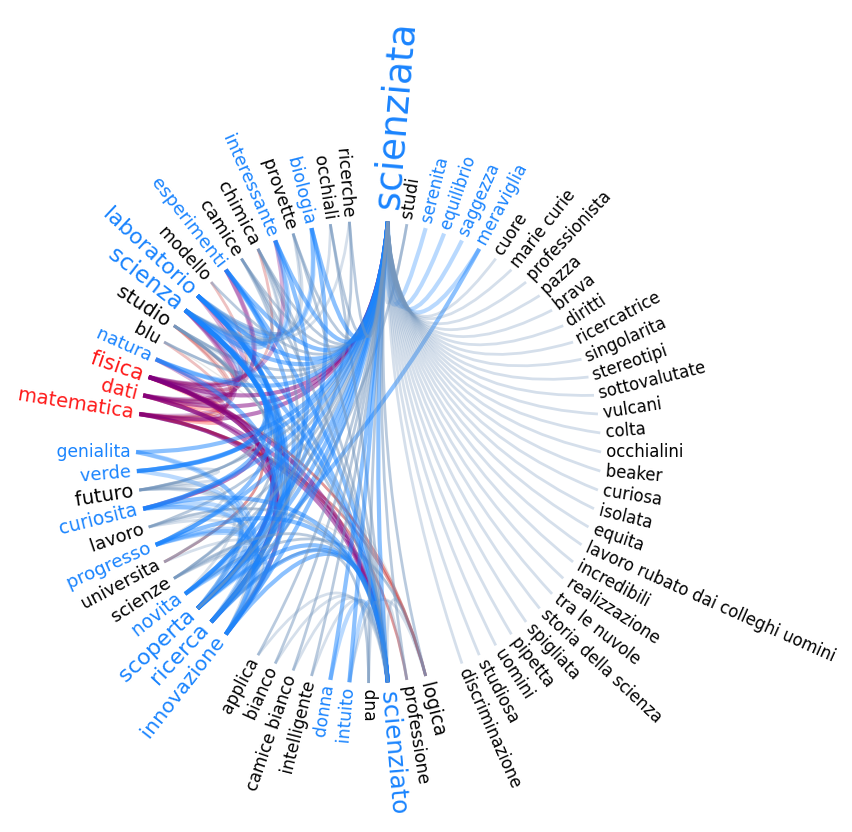

Local clustering scienziata: 0.053923541247484906
Degree scienziata: 71
Counts of 'scienziata' = {'positive': 22, 'negative': 3, 'neutral': 47}
Mode of 'scienziata' = neutral


In [59]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=data_female_2025,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/females_2025",
    flower="no",
)

Number of unique words: 1131


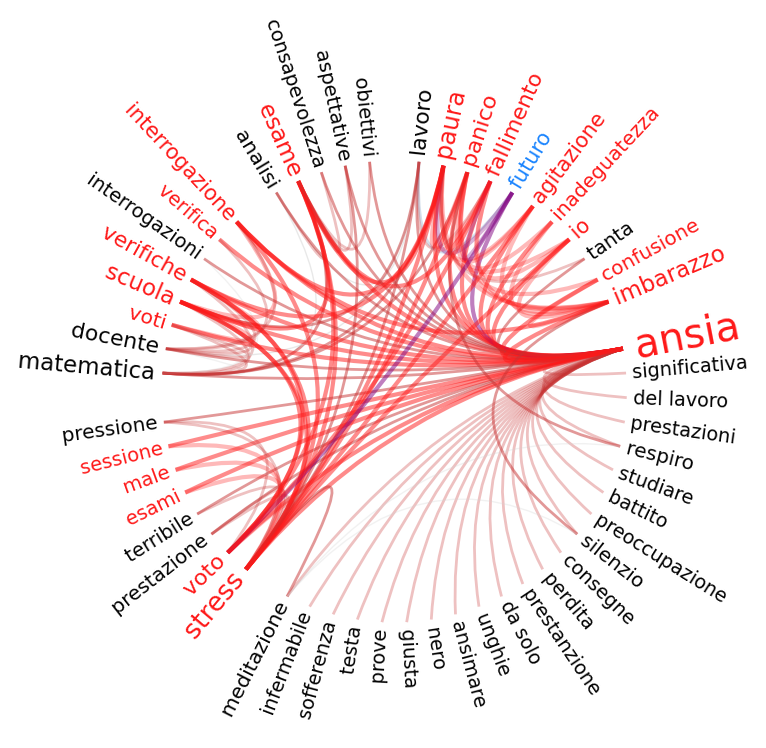

Local clustering ansia: 0.057329462989840346
Degree ansia: 53
Counts of 'ansia' = {'positive': 1, 'negative': 20, 'neutral': 33}
Mode of 'ansia' = neutral


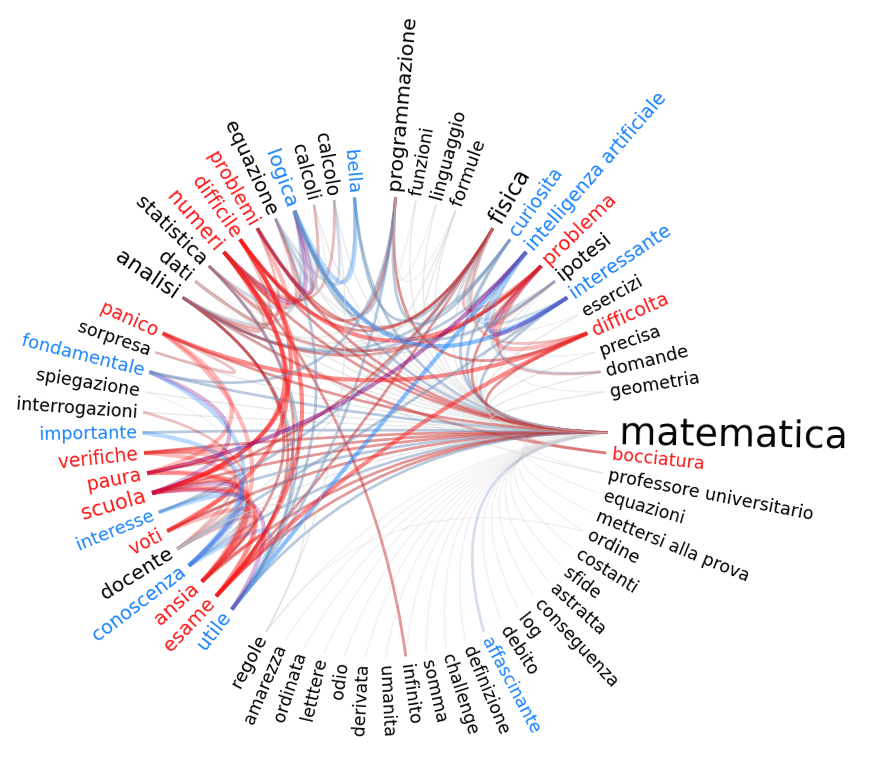

Local clustering matematica: 0.05721153846153846
Degree matematica: 65
Counts of 'matematica' = {'positive': 11, 'negative': 13, 'neutral': 42}
Mode of 'matematica' = neutral


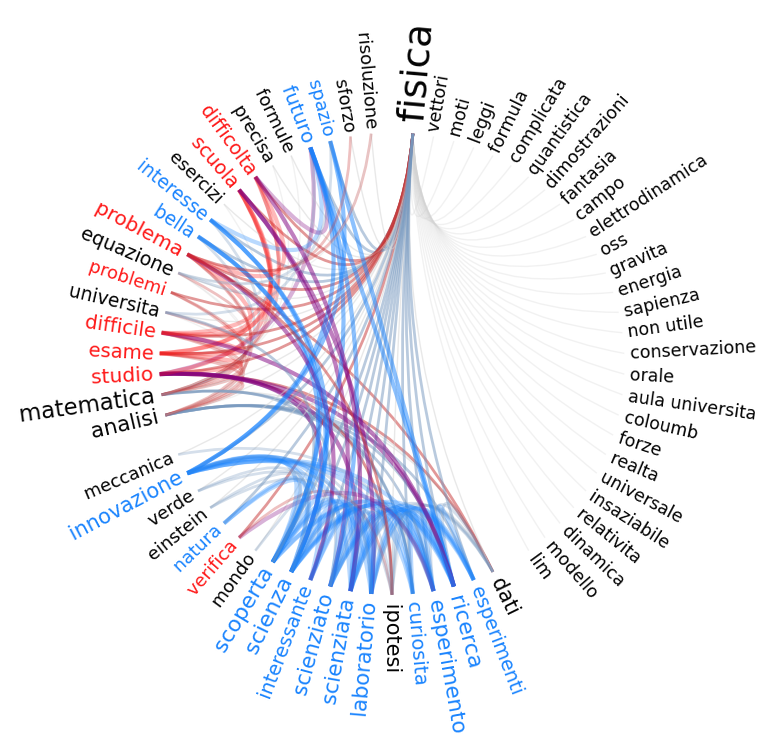

Local clustering fisica: 0.06153846153846154
Degree fisica: 66
Counts of 'fisica' = {'positive': 16, 'negative': 8, 'neutral': 43}
Mode of 'fisica' = neutral


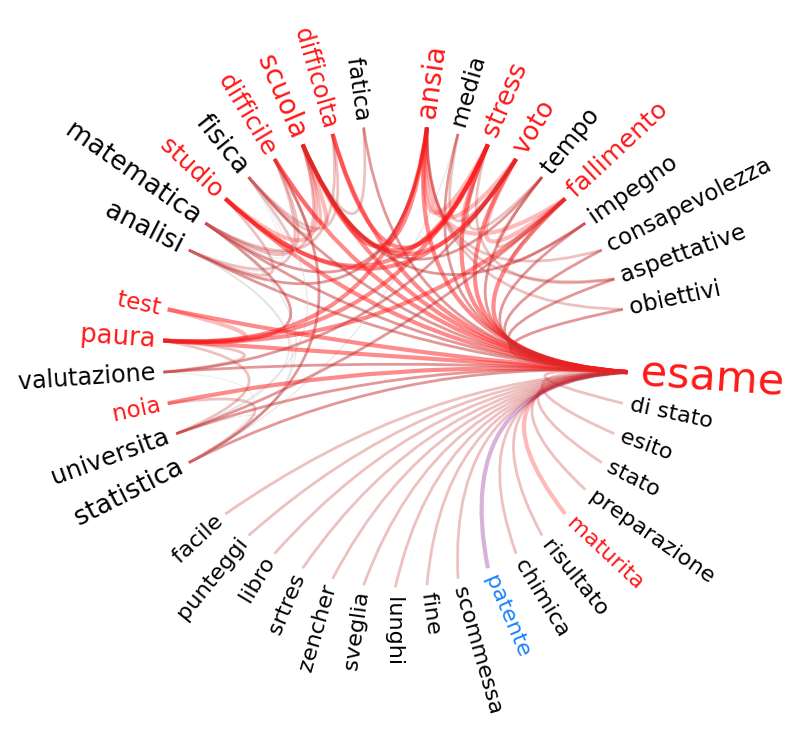

Local clustering esame: 0.06829268292682927
Degree esame: 41
Counts of 'esame' = {'positive': 1, 'negative': 13, 'neutral': 28}
Mode of 'esame' = neutral


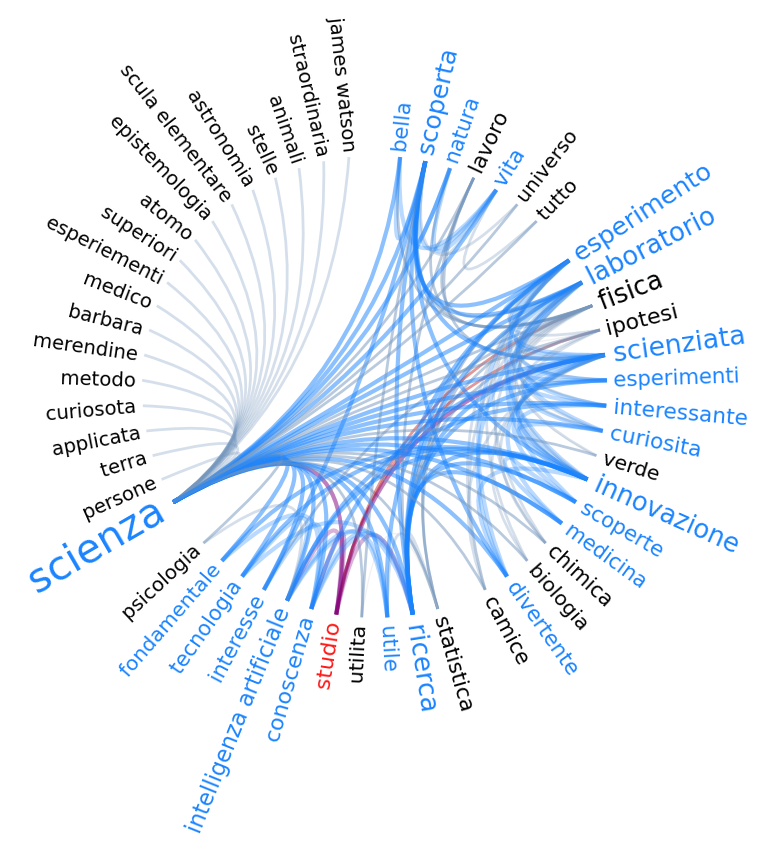

Local clustering scienza: 0.07616892911010557
Degree scienza: 52
Counts of 'scienza' = {'positive': 22, 'negative': 1, 'neutral': 30}
Mode of 'scienza' = neutral


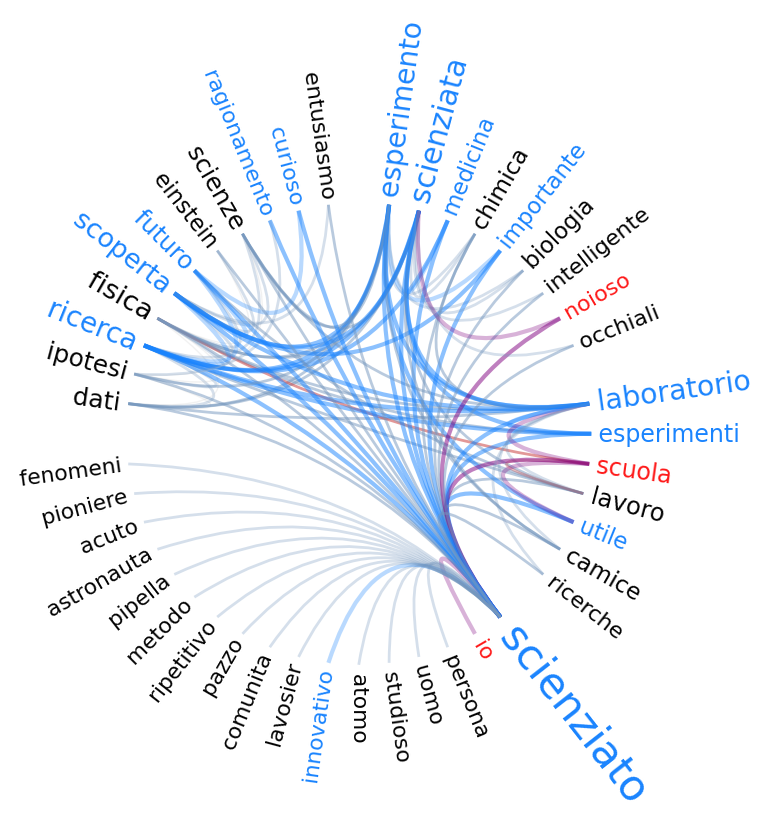

Local clustering scienziato: 0.07419712070874862
Degree scienziato: 43
Counts of 'scienziato' = {'positive': 14, 'negative': 3, 'neutral': 27}
Mode of 'scienziato' = neutral


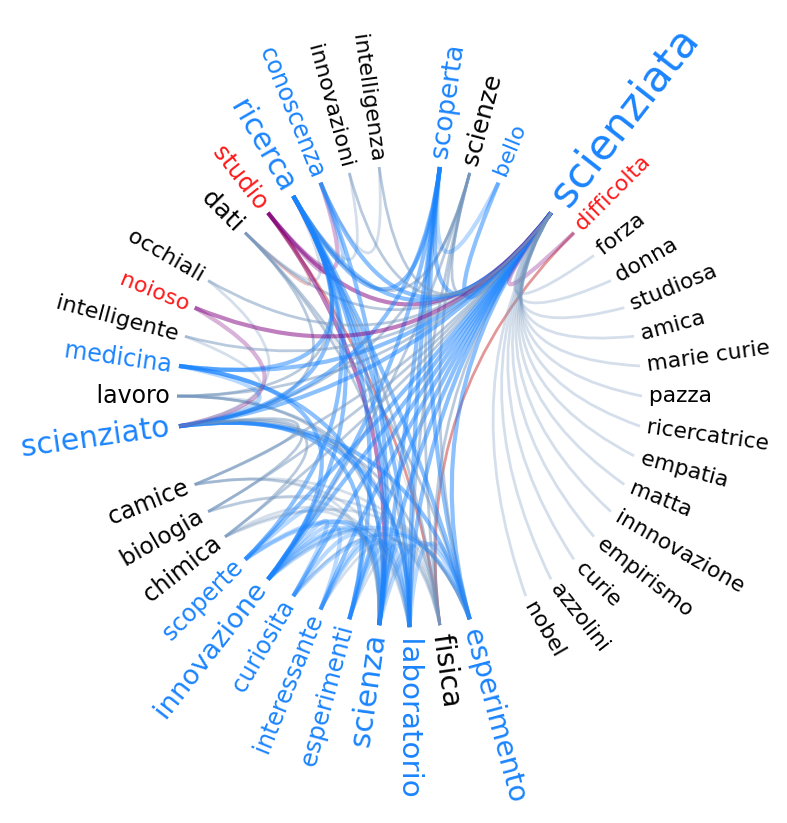

Local clustering scienziata: 0.10104529616724739
Degree scienziata: 42
Counts of 'scienziata' = {'positive': 15, 'negative': 3, 'neutral': 25}
Mode of 'scienziata' = neutral


In [60]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=data_male_2025,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/males_2025",
    flower="no",
)

Number of unique words: 1542


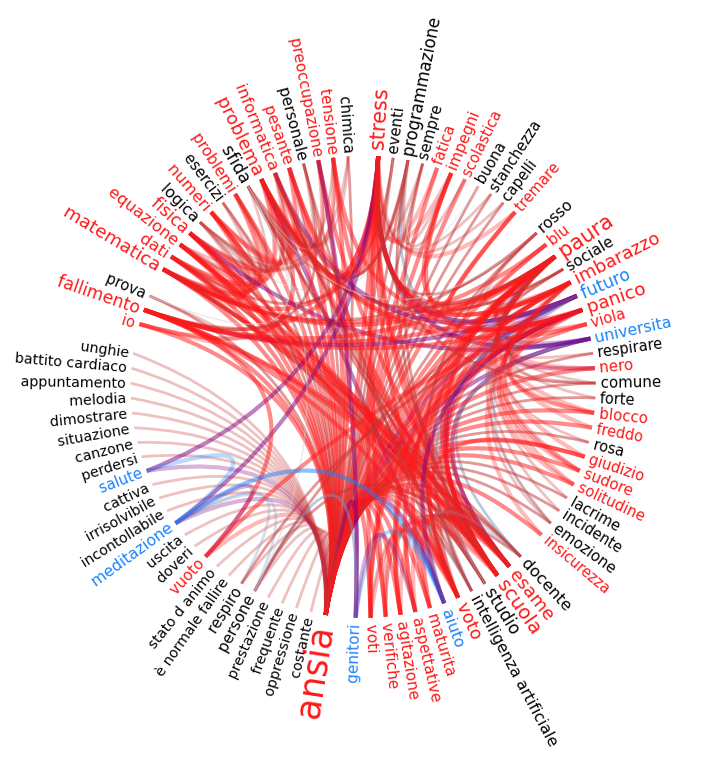

Local clustering ansia: 0.05493133583021224
Degree ansia: 90
Counts of 'ansia' = {'positive': 6, 'negative': 40, 'neutral': 45}
Mode of 'ansia' = neutral


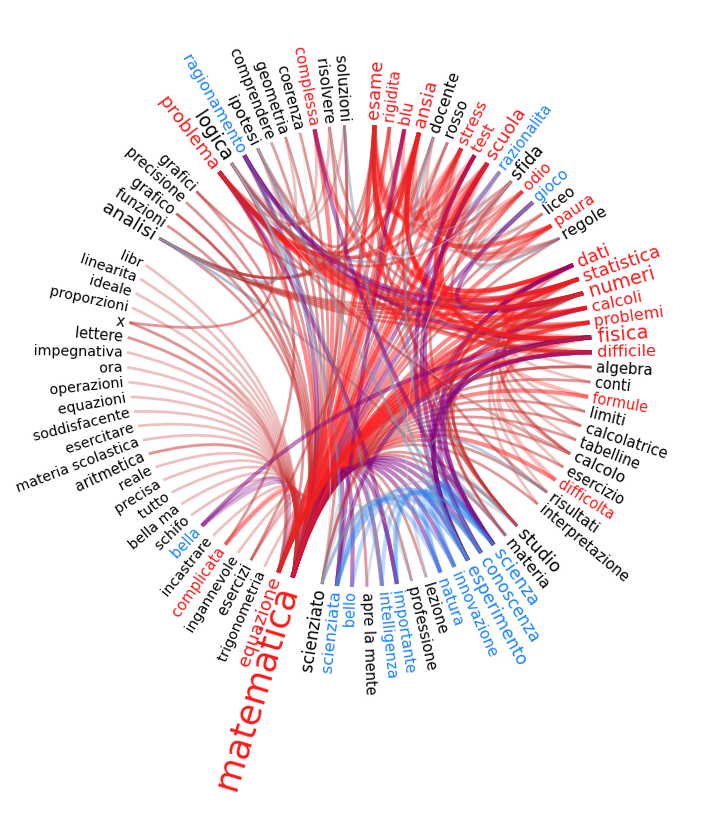

Local clustering matematica: 0.05518102372034956
Degree matematica: 90
Counts of 'matematica' = {'positive': 13, 'negative': 23, 'neutral': 55}
Mode of 'matematica' = neutral


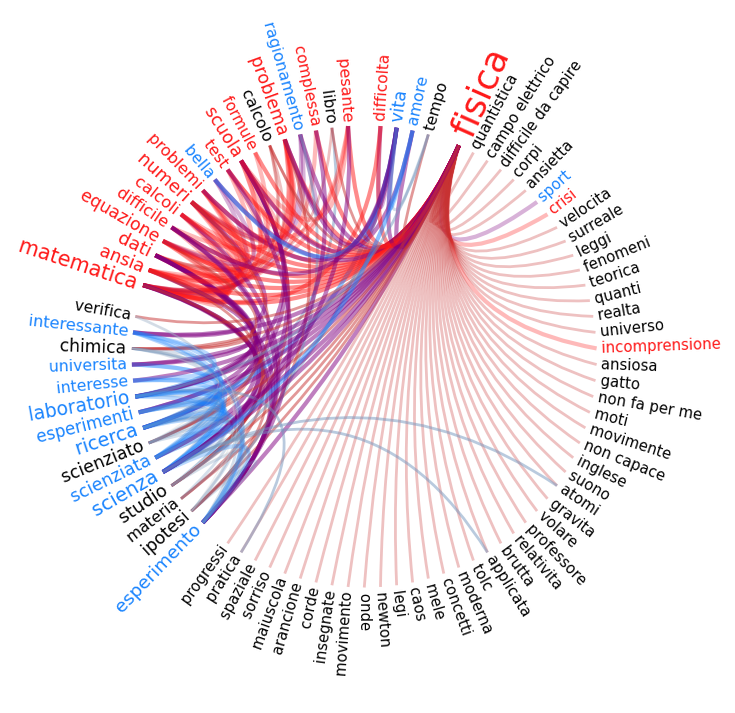

Local clustering fisica: 0.04005602240896359
Degree fisica: 85
Counts of 'fisica' = {'positive': 14, 'negative': 18, 'neutral': 54}
Mode of 'fisica' = neutral


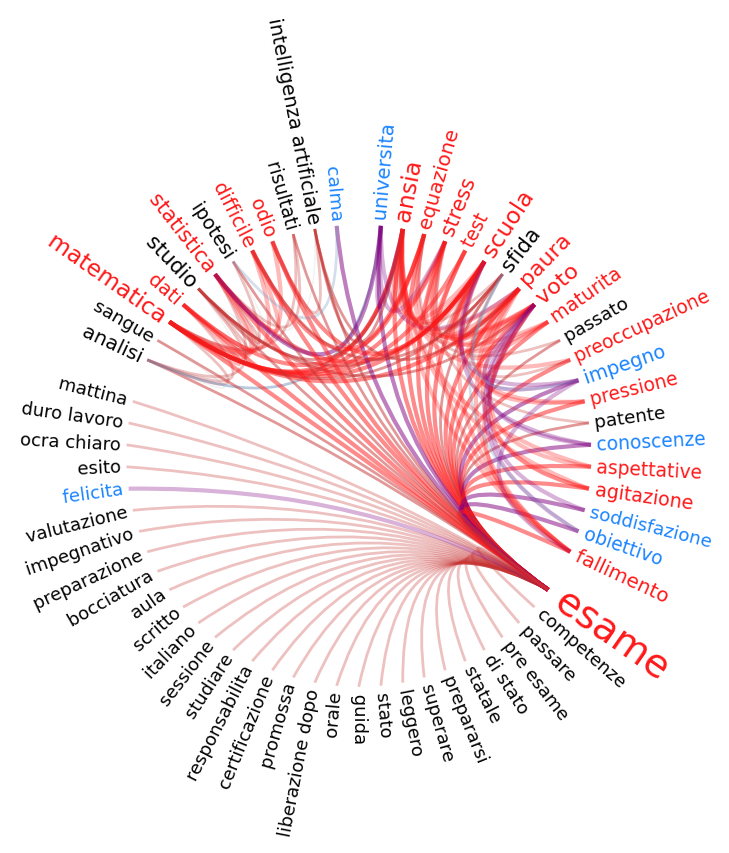

Local clustering esame: 0.046536224219989424
Degree esame: 62
Counts of 'esame' = {'positive': 7, 'negative': 19, 'neutral': 37}
Mode of 'esame' = neutral


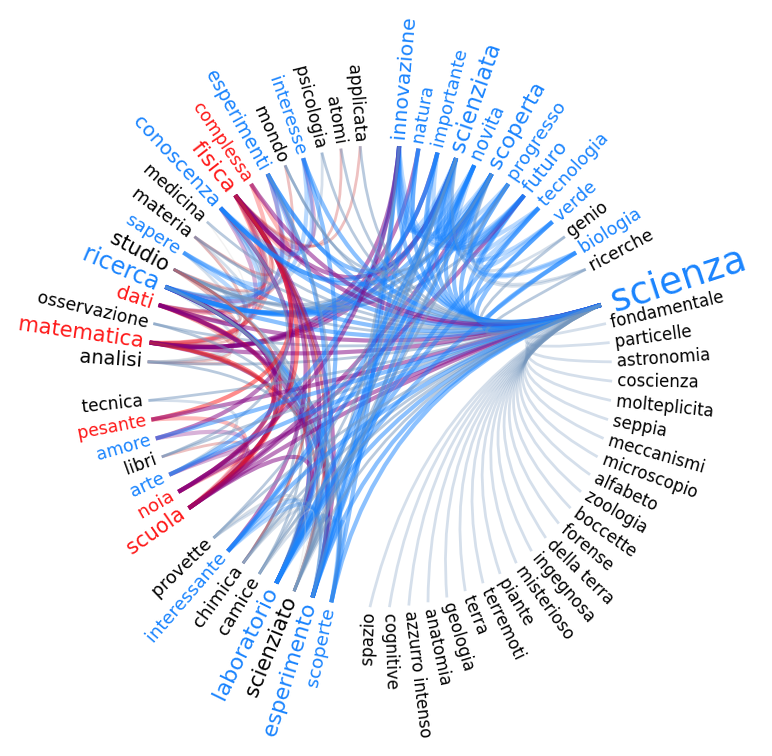

Local clustering scienza: 0.06990622335890878
Degree scienza: 69
Counts of 'scienza' = {'positive': 23, 'negative': 7, 'neutral': 40}
Mode of 'scienza' = neutral


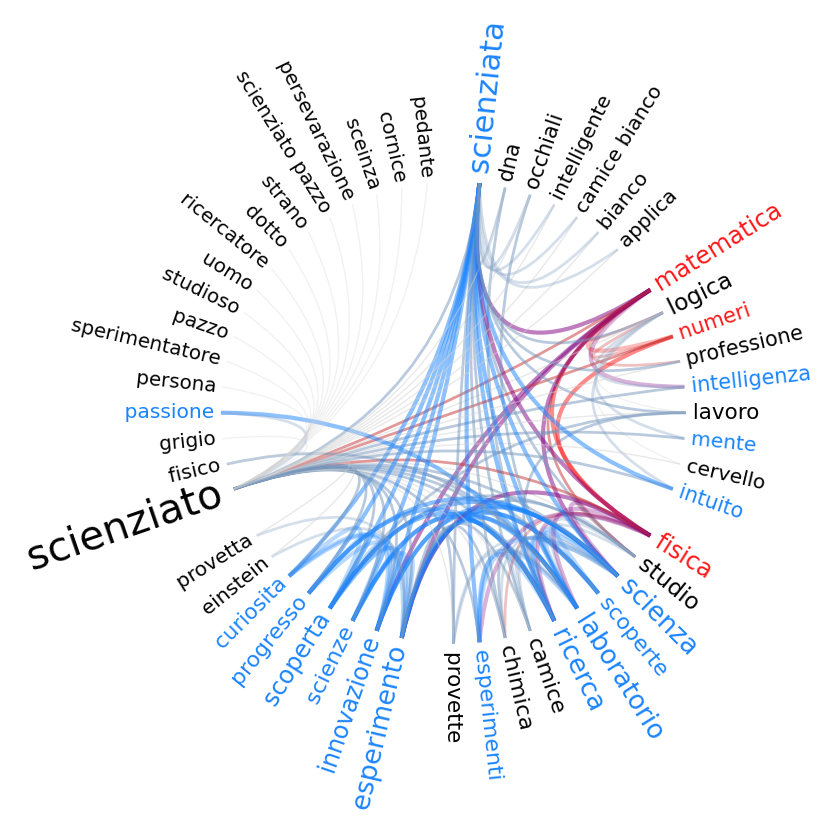

Local clustering scienziato: 0.08489795918367347
Degree scienziato: 50
Counts of 'scienziato' = {'positive': 16, 'negative': 3, 'neutral': 32}
Mode of 'scienziato' = neutral


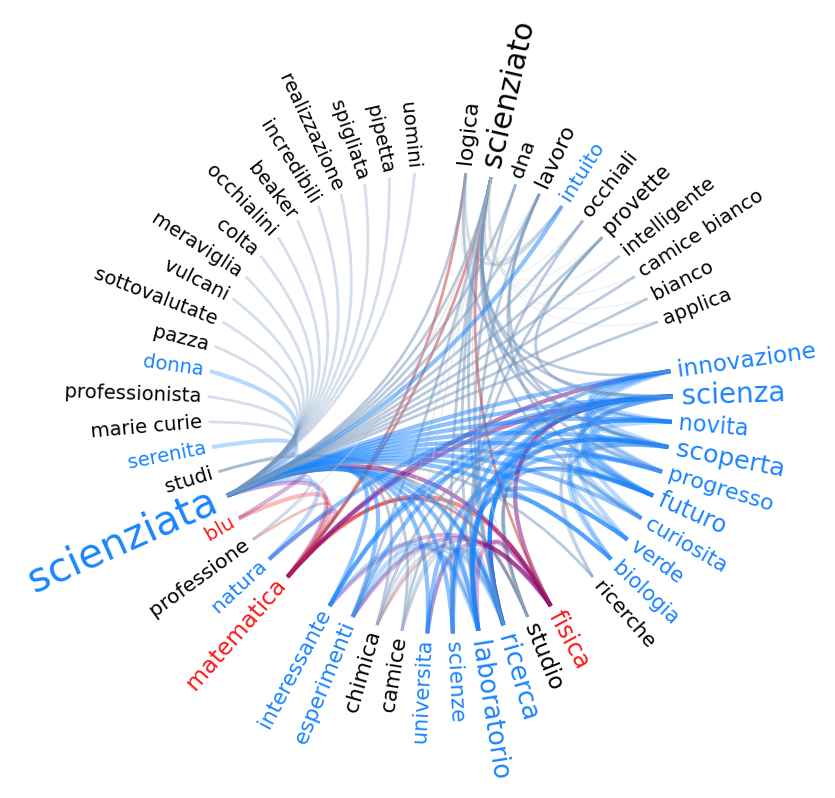

Local clustering scienziata: 0.08144796380090498
Degree scienziata: 52
Counts of 'scienziata' = {'positive': 20, 'negative': 3, 'neutral': 30}
Mode of 'scienziata' = neutral


In [62]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=females_2025_liceo,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/liceo_females",
    flower="no",
)

Number of unique words: 924


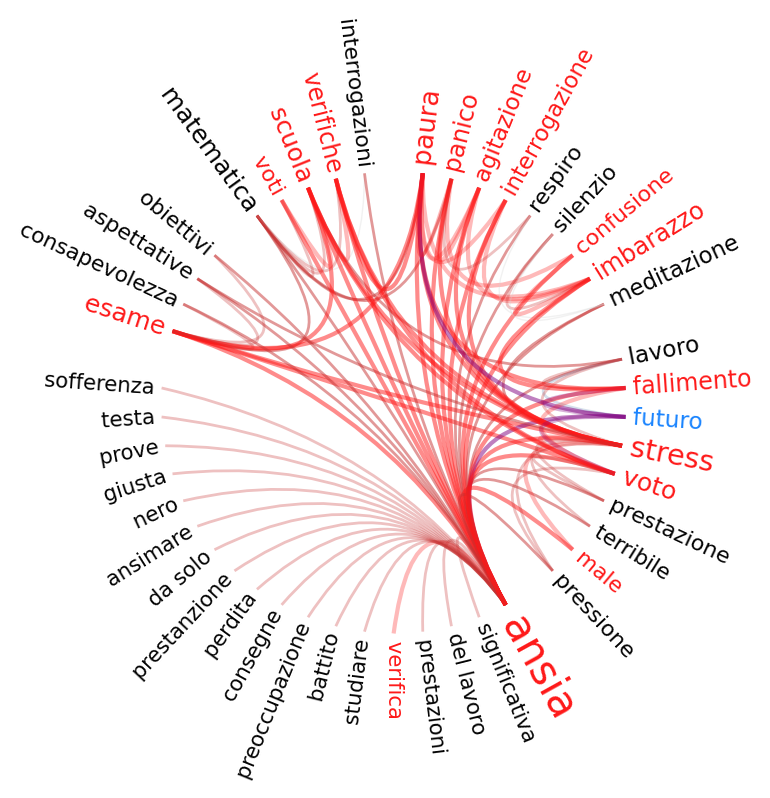

Local clustering ansia: 0.06025369978858351
Degree ansia: 44
Counts of 'ansia' = {'positive': 1, 'negative': 16, 'neutral': 28}
Mode of 'ansia' = neutral


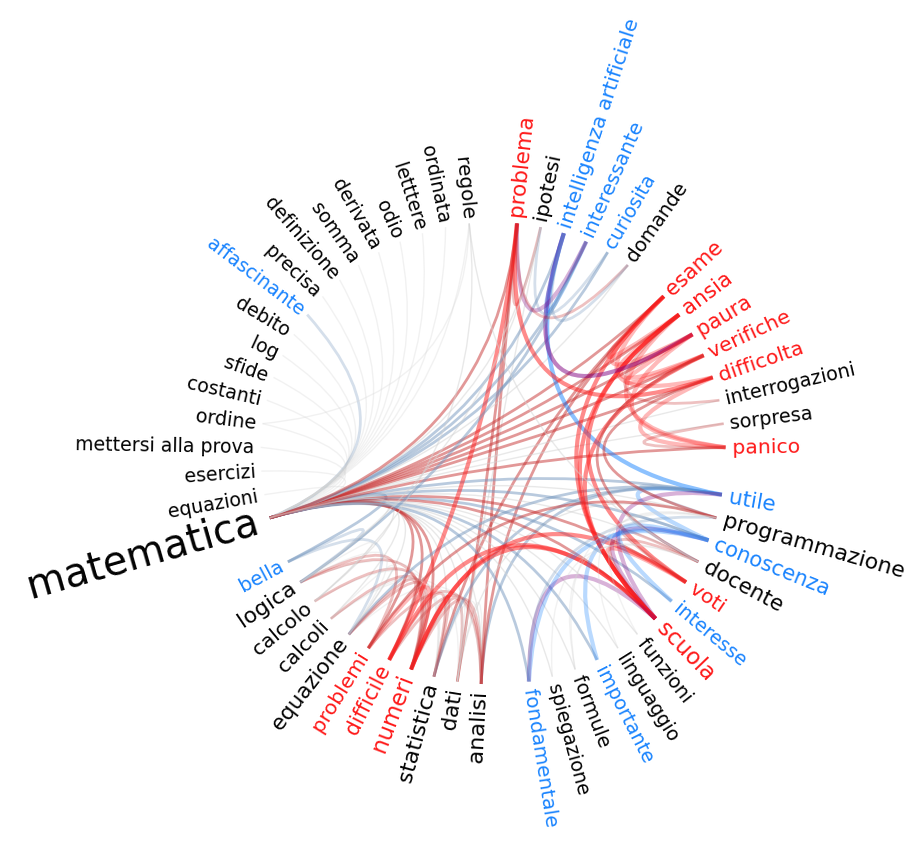

Local clustering matematica: 0.059932659932659935
Degree matematica: 55
Counts of 'matematica' = {'positive': 10, 'negative': 12, 'neutral': 34}
Mode of 'matematica' = neutral


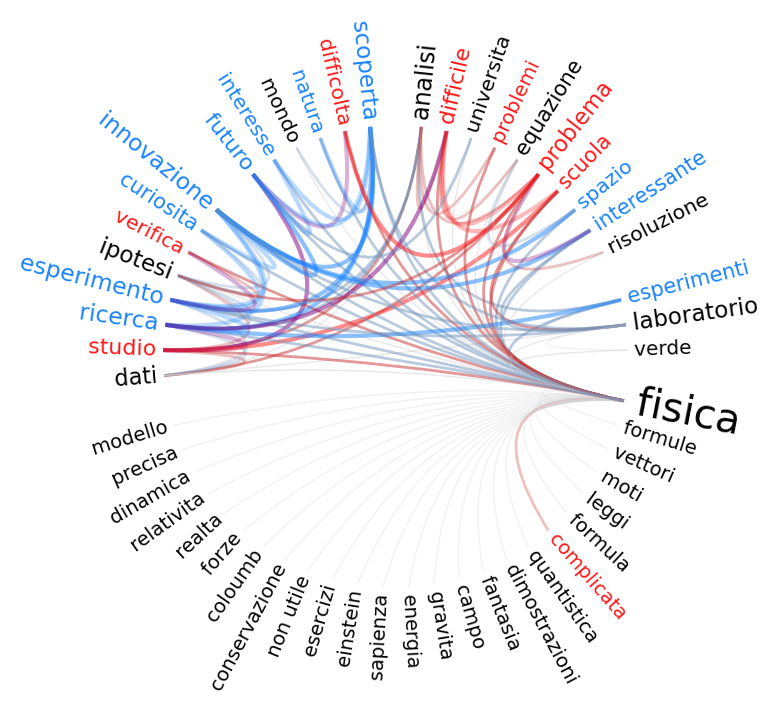

Local clustering fisica: 0.04862745098039216
Degree fisica: 51
Counts of 'fisica' = {'positive': 11, 'negative': 8, 'neutral': 33}
Mode of 'fisica' = neutral


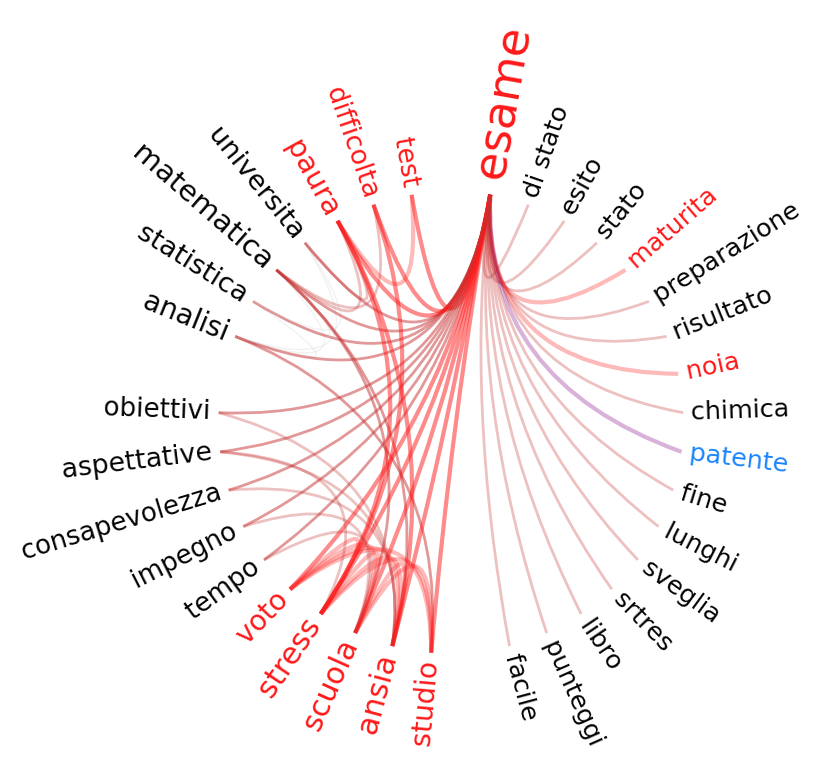

Local clustering esame: 0.056818181818181816
Degree esame: 33
Counts of 'esame' = {'positive': 1, 'negative': 11, 'neutral': 22}
Mode of 'esame' = neutral


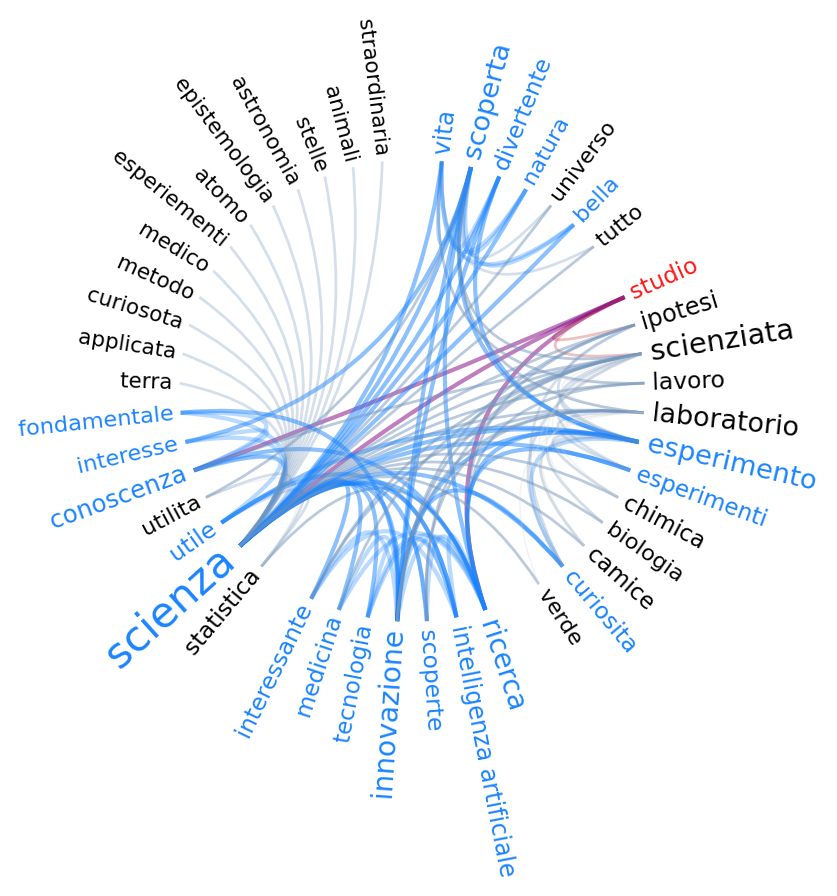

Local clustering scienza: 0.08350951374207188
Degree scienza: 44
Counts of 'scienza' = {'positive': 20, 'negative': 1, 'neutral': 24}
Mode of 'scienza' = neutral


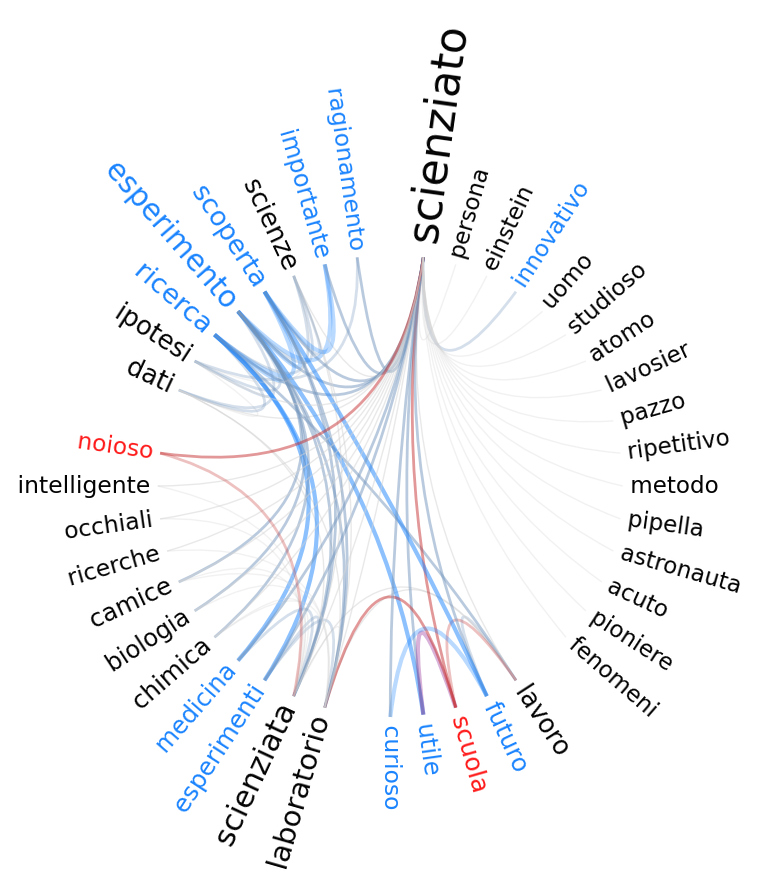

Local clustering scienziato: 0.06882591093117409
Degree scienziato: 39
Counts of 'scienziato' = {'positive': 11, 'negative': 2, 'neutral': 27}
Mode of 'scienziato' = neutral


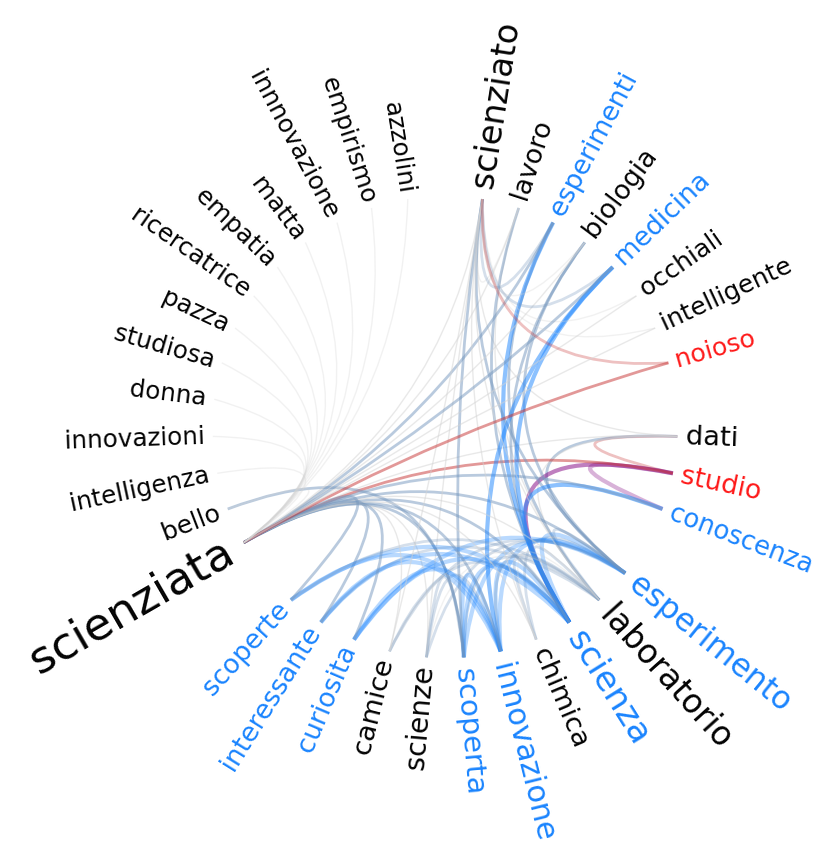

Local clustering scienziata: 0.10338680926916222
Degree scienziata: 34
Counts of 'scienziata' = {'positive': 10, 'negative': 2, 'neutral': 23}
Mode of 'scienziata' = neutral


In [63]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=males_2025_liceo,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/liceo_males",
    flower="no",
)

Number of unique words: 622


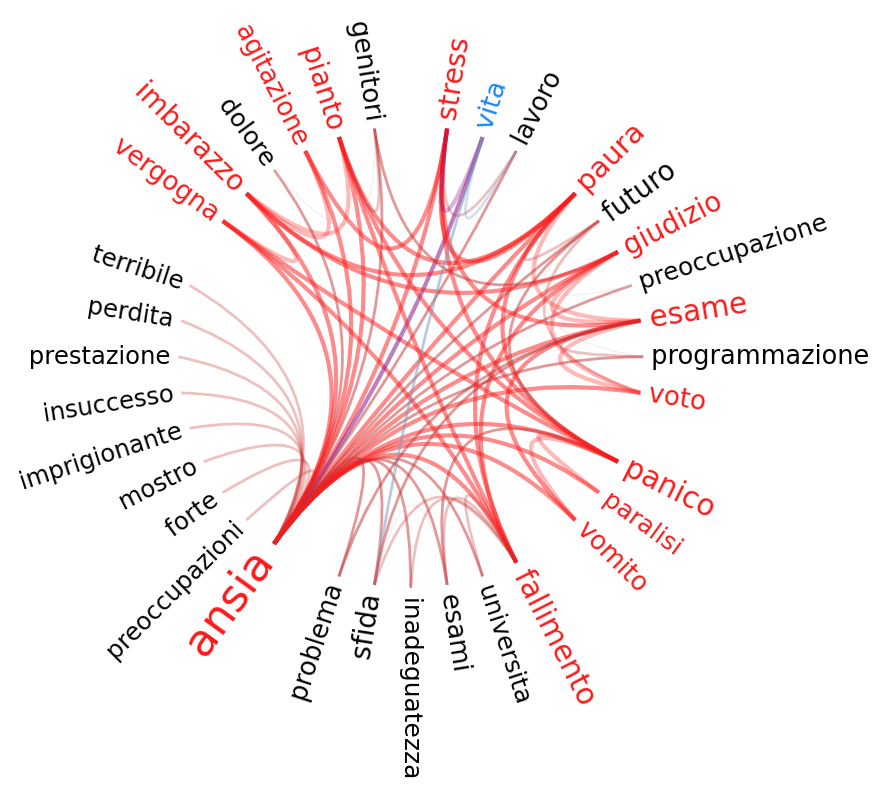

Local clustering ansia: 0.08712121212121213
Degree ansia: 33
Counts of 'ansia' = {'positive': 1, 'negative': 14, 'neutral': 19}
Mode of 'ansia' = neutral


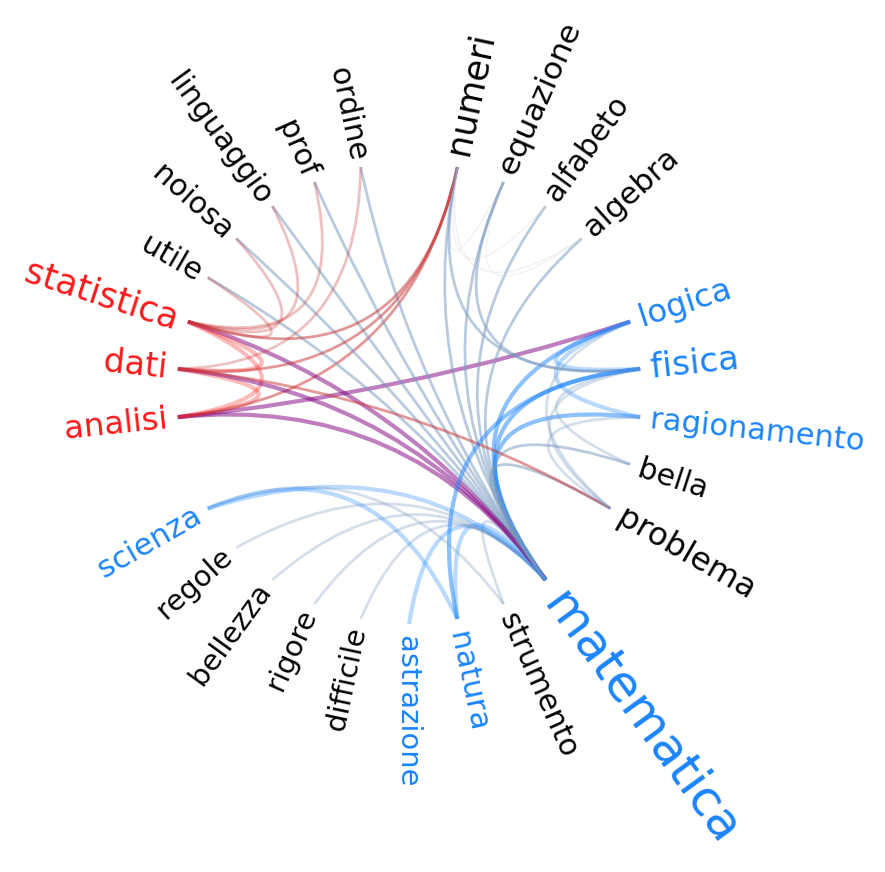

Local clustering matematica: 0.09333333333333334
Degree matematica: 25
Counts of 'matematica' = {'positive': 7, 'negative': 3, 'neutral': 16}
Mode of 'matematica' = neutral


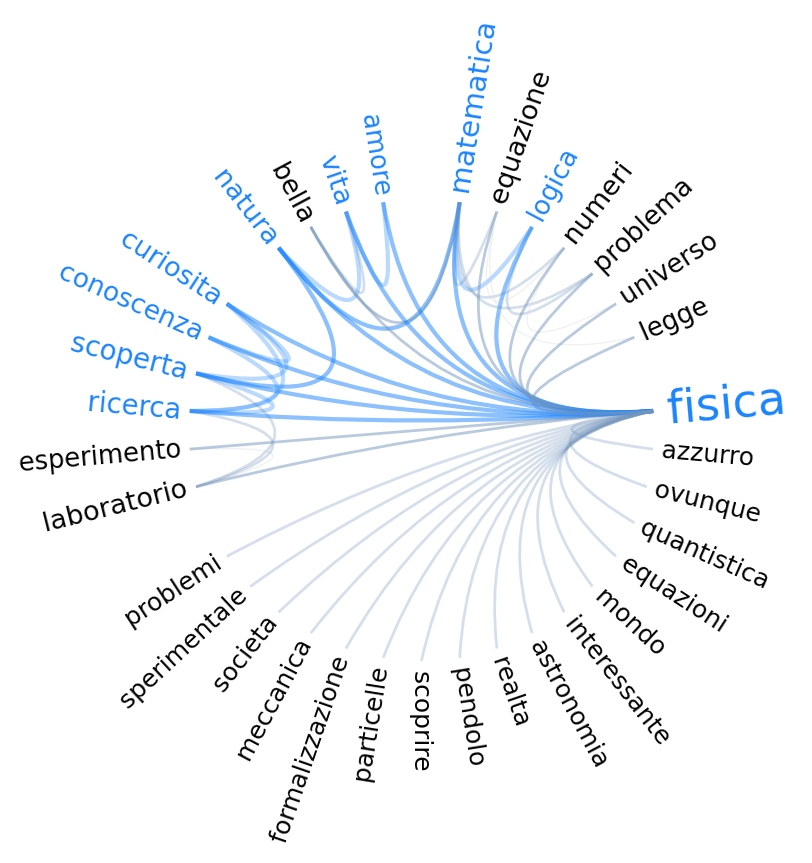

Local clustering fisica: 0.041666666666666664
Degree fisica: 33
Counts of 'fisica' = {'positive': 10, 'negative': 0, 'neutral': 24}
Mode of 'fisica' = neutral


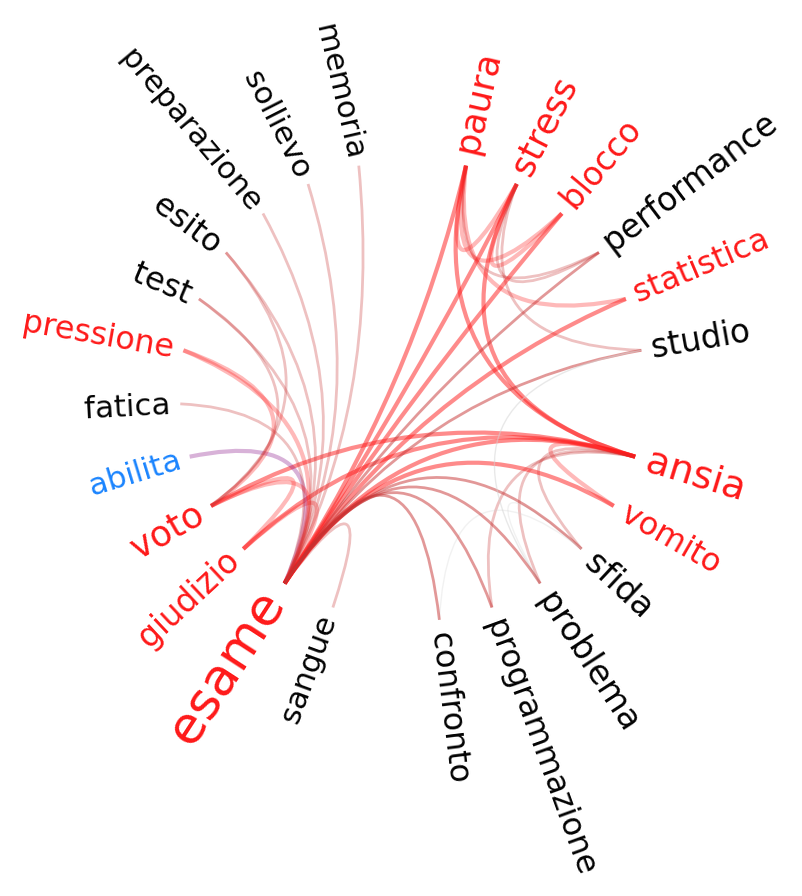

Local clustering esame: 0.08695652173913043
Degree esame: 23
Counts of 'esame' = {'positive': 1, 'negative': 10, 'neutral': 13}
Mode of 'esame' = neutral


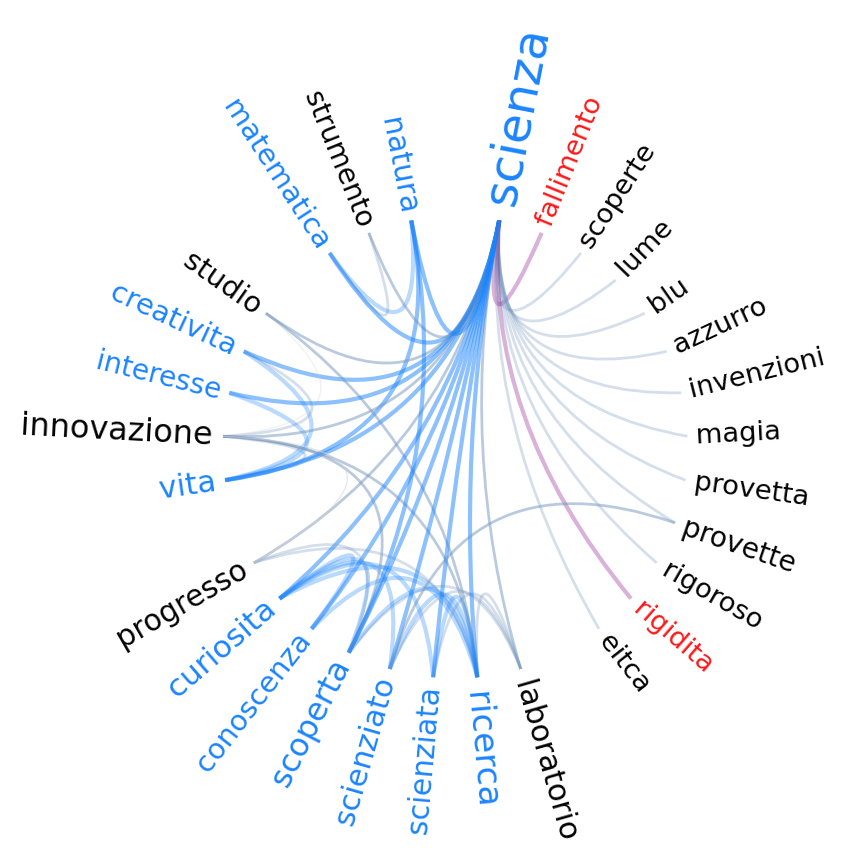

Local clustering scienza: 0.07671957671957672
Degree scienza: 28
Counts of 'scienza' = {'positive': 12, 'negative': 2, 'neutral': 15}
Mode of 'scienza' = neutral


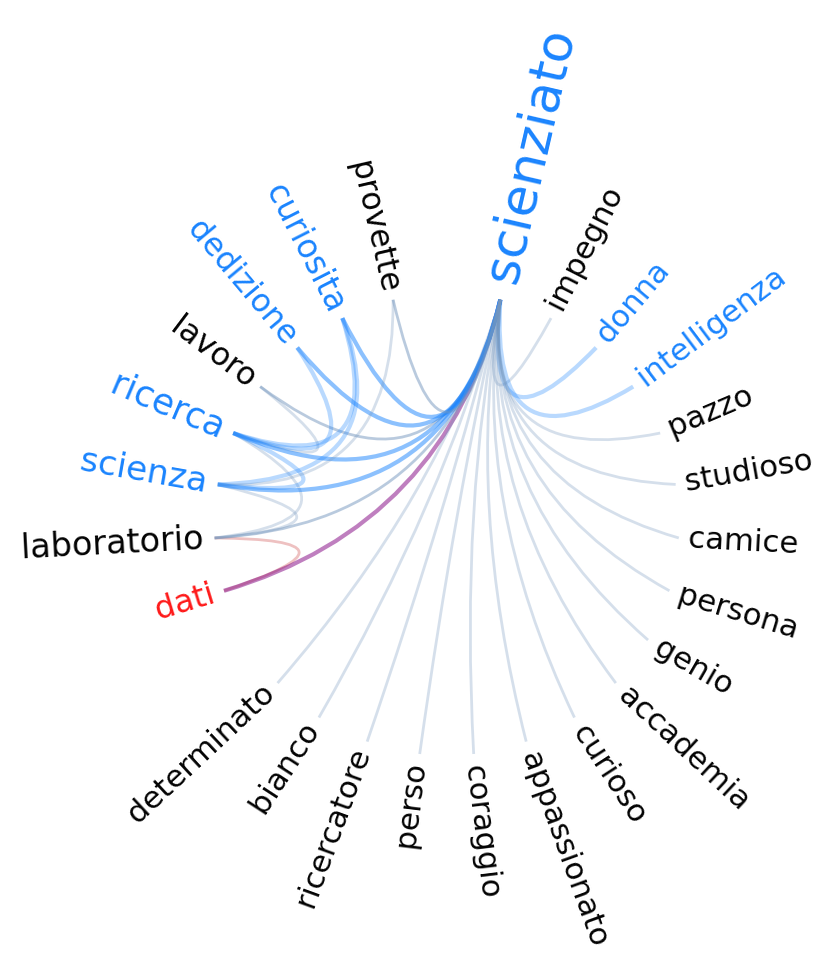

Local clustering scienziato: 0.03260869565217391
Degree scienziato: 24
Counts of 'scienziato' = {'positive': 7, 'negative': 1, 'neutral': 17}
Mode of 'scienziato' = neutral


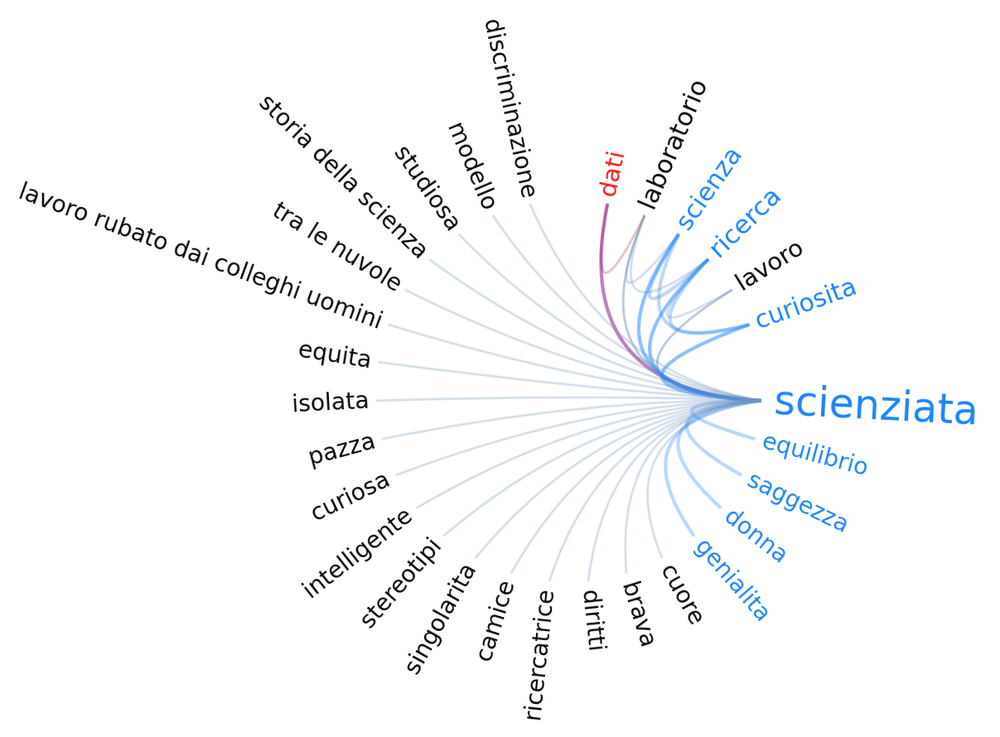

Local clustering scienziata: 0.018518518518518517
Degree scienziata: 28
Counts of 'scienziata' = {'positive': 8, 'negative': 1, 'neutral': 20}
Mode of 'scienziata' = neutral


In [65]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=fisica_female,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/fisica_females",
    flower="no",
)

Number of unique words: 391


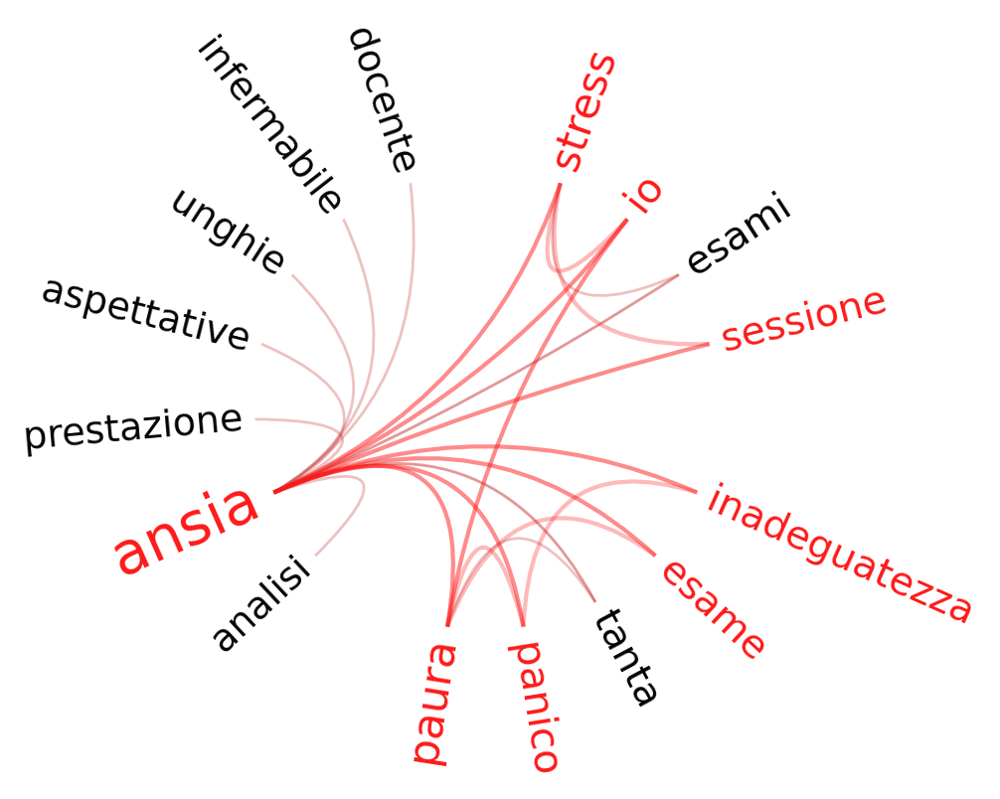

Local clustering ansia: 0.0761904761904762
Degree ansia: 15
Counts of 'ansia' = {'positive': 0, 'negative': 8, 'neutral': 8}
Mode of 'ansia' = negative


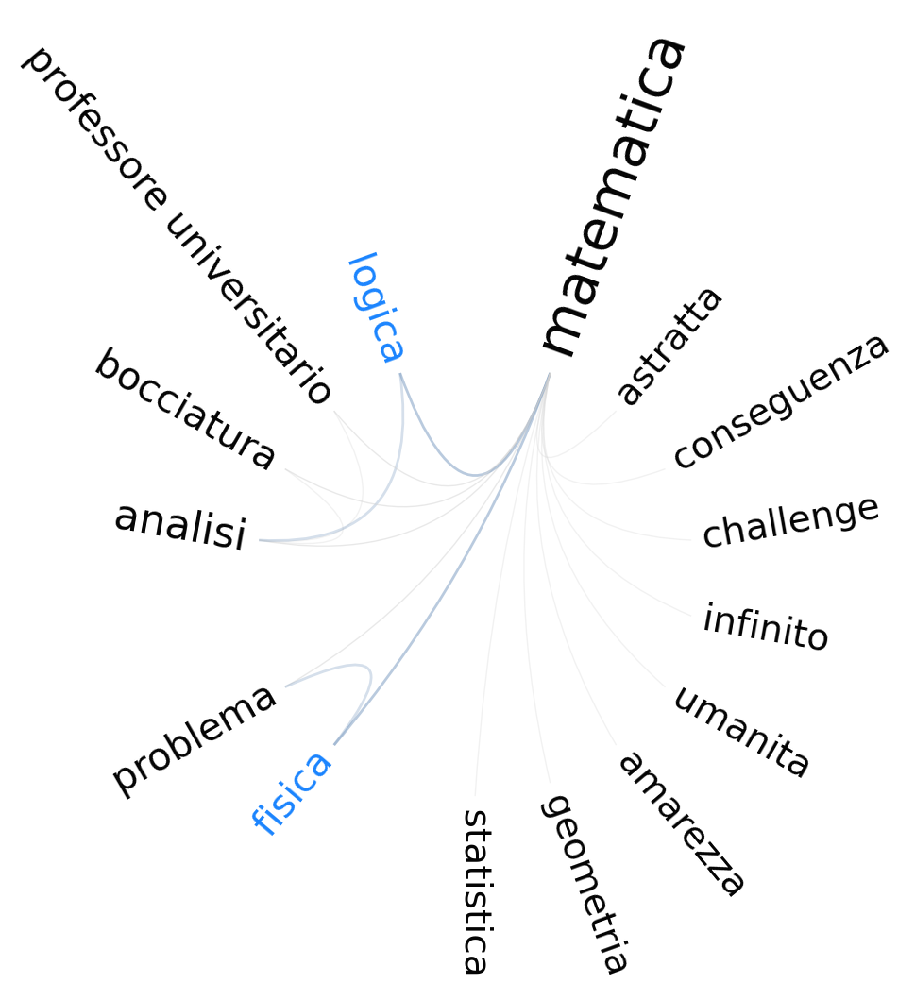

Local clustering matematica: 0.04395604395604396
Degree matematica: 14
Counts of 'matematica' = {'positive': 2, 'negative': 0, 'neutral': 13}
Mode of 'matematica' = neutral


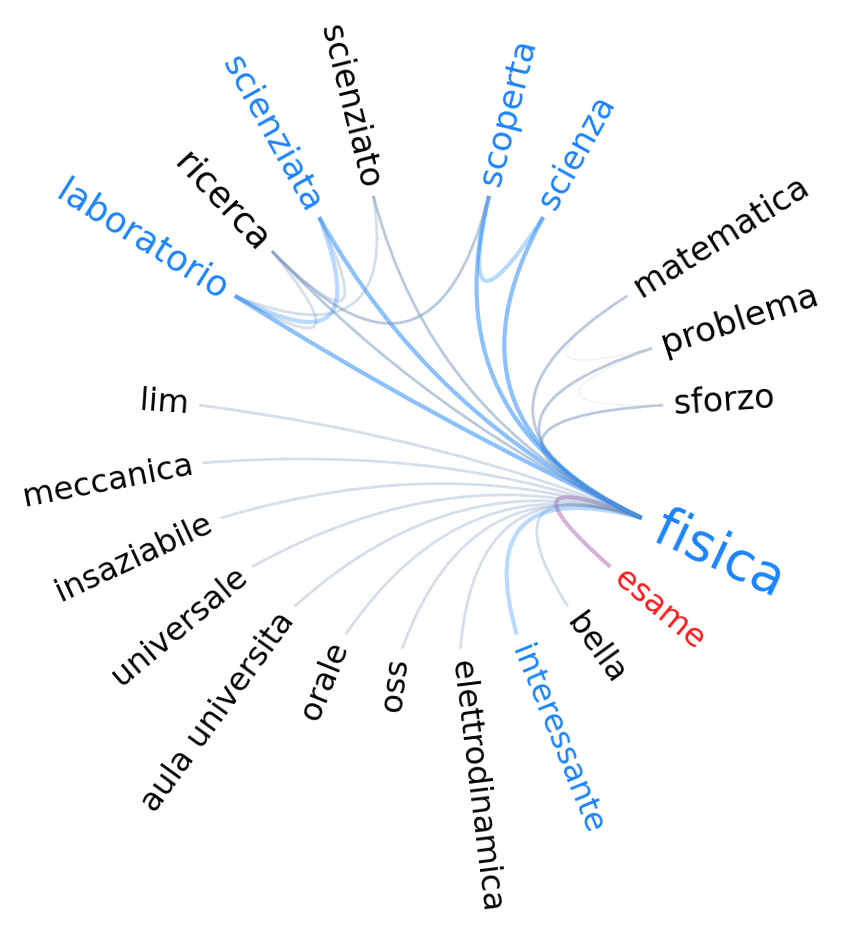

Local clustering fisica: 0.042105263157894736
Degree fisica: 20
Counts of 'fisica' = {'positive': 6, 'negative': 1, 'neutral': 14}
Mode of 'fisica' = neutral


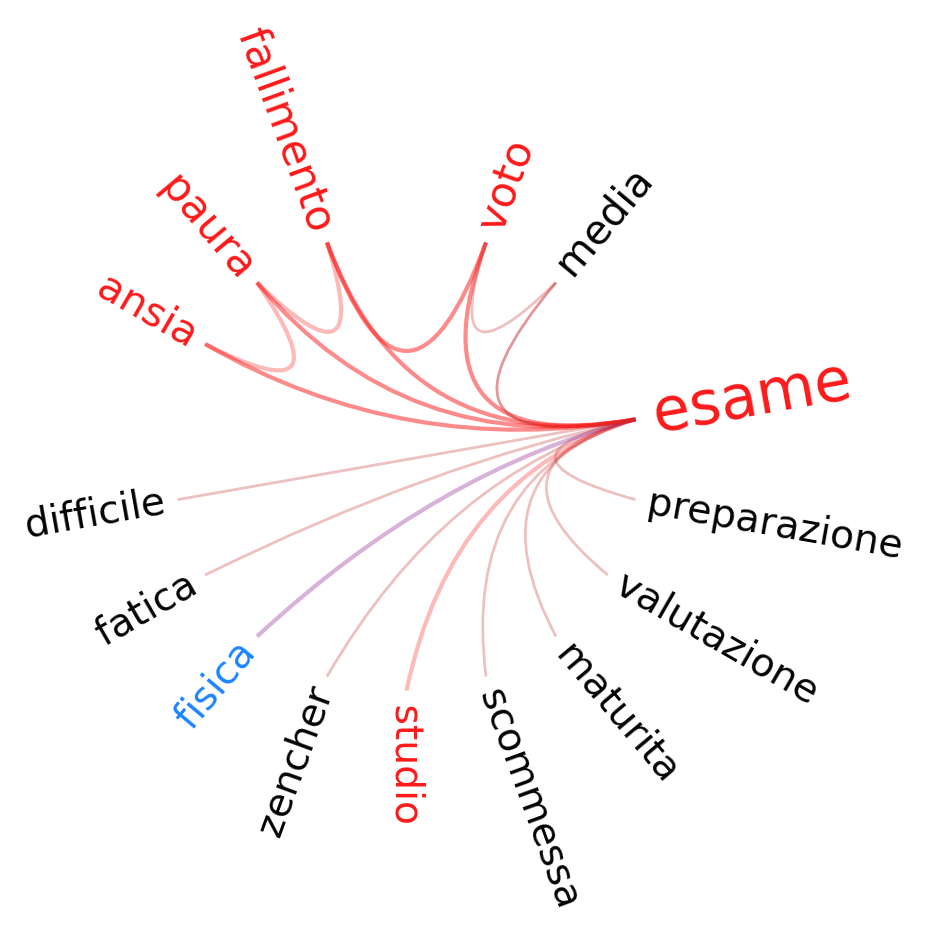

Local clustering esame: 0.04395604395604396
Degree esame: 14
Counts of 'esame' = {'positive': 1, 'negative': 6, 'neutral': 8}
Mode of 'esame' = neutral


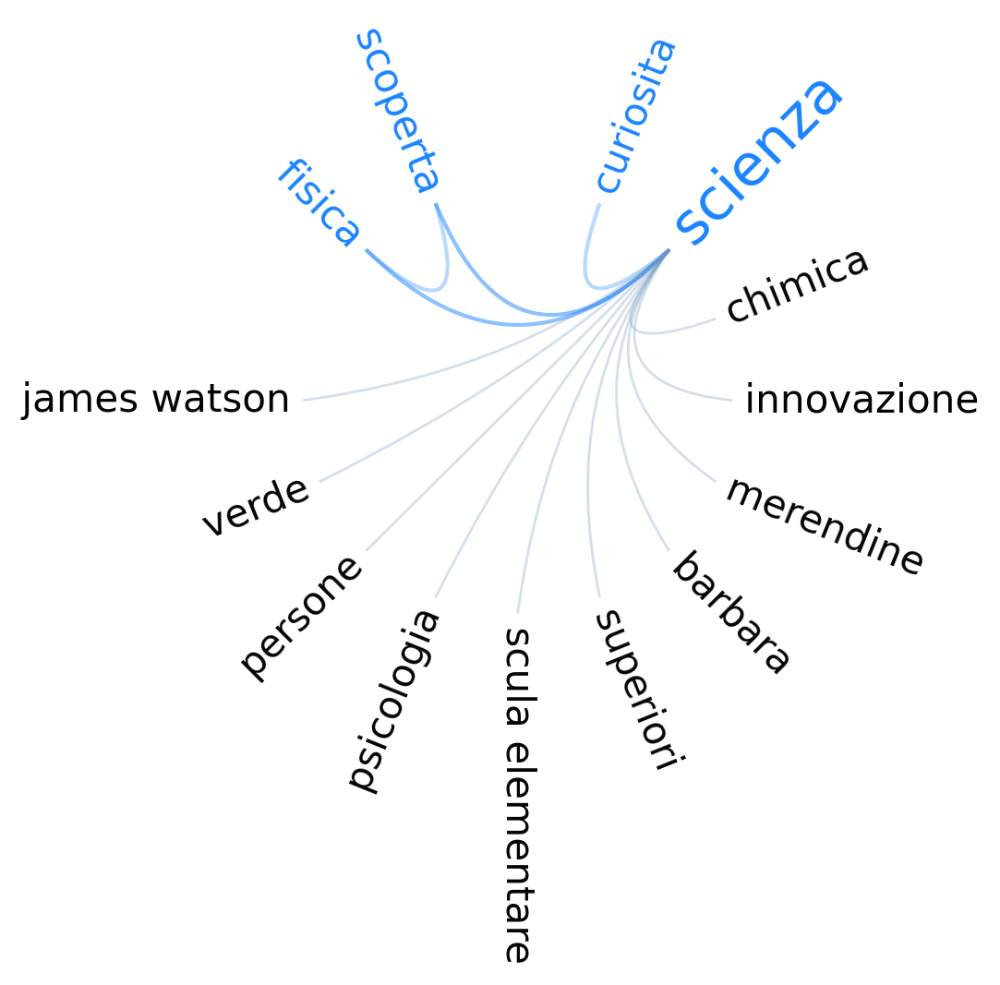

Local clustering scienza: 0.01282051282051282
Degree scienza: 13
Counts of 'scienza' = {'positive': 4, 'negative': 0, 'neutral': 10}
Mode of 'scienza' = neutral


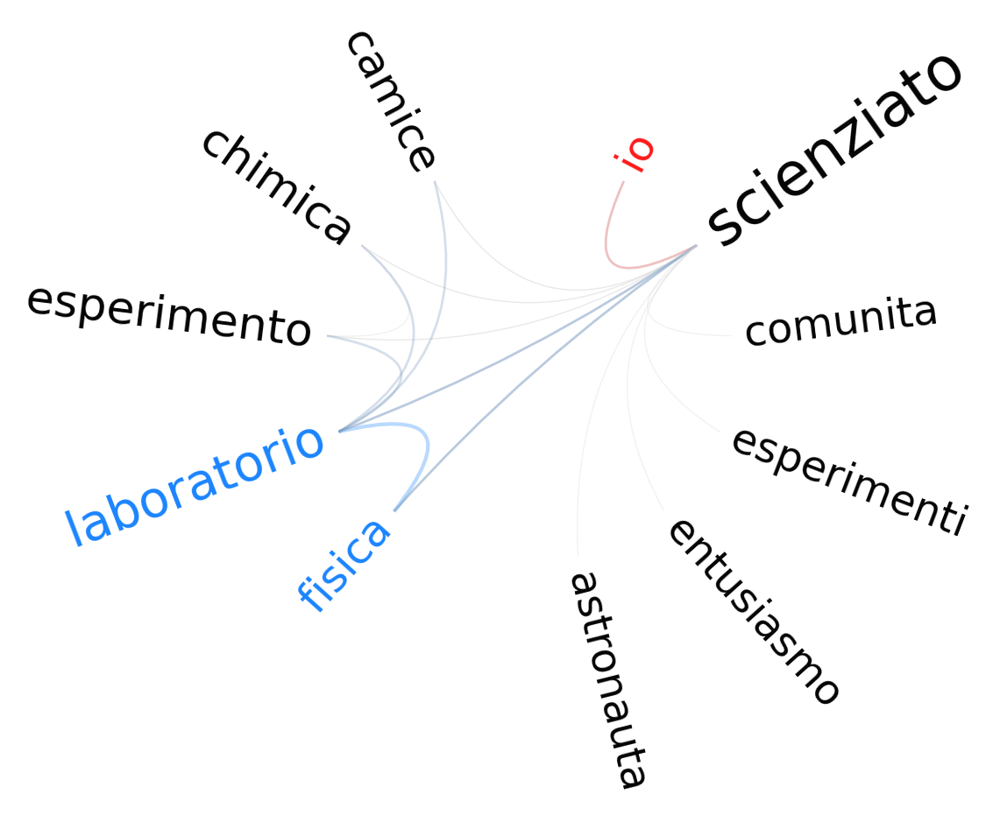

Local clustering scienziato: 0.1111111111111111
Degree scienziato: 10
Counts of 'scienziato' = {'positive': 2, 'negative': 1, 'neutral': 8}
Mode of 'scienziato' = neutral


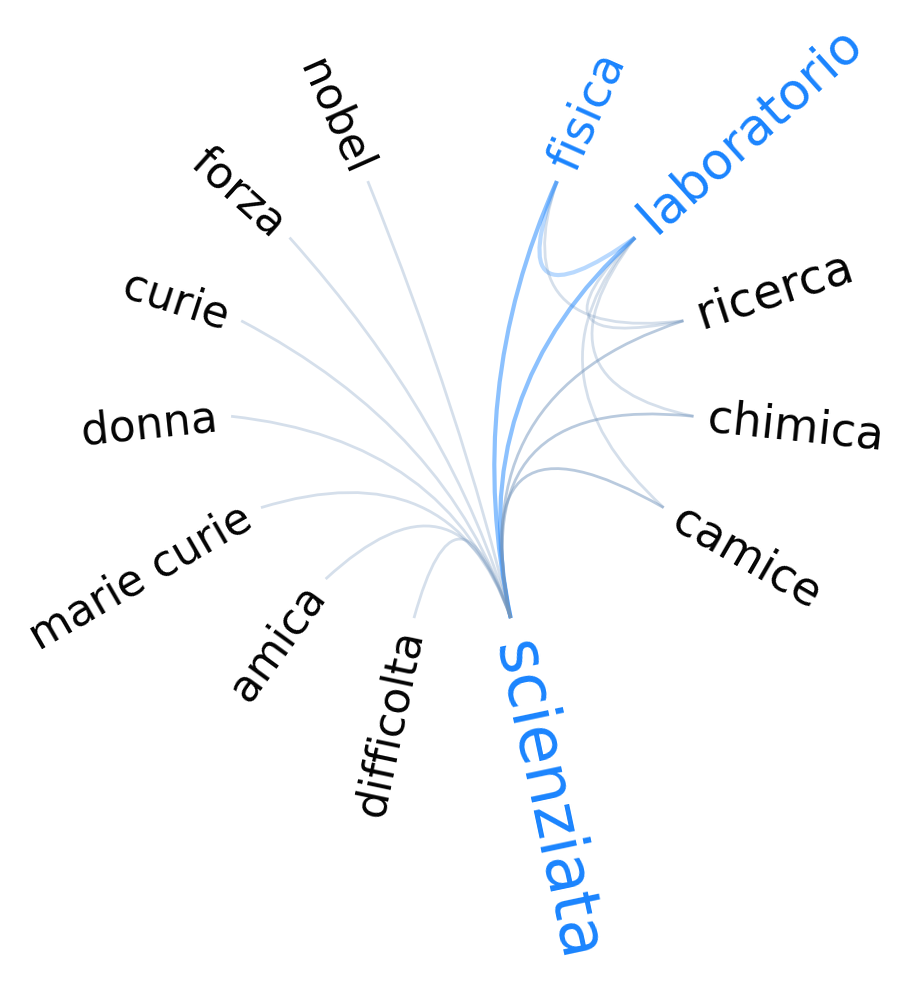

Local clustering scienziata: 0.07575757575757576
Degree scienziata: 12
Counts of 'scienziata' = {'positive': 3, 'negative': 0, 'neutral': 10}
Mode of 'scienziata' = neutral


In [11]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=fisica_male,
    keywords=keywords + ["scienziato", "scienziata"],
    folder_path=RESSERENO_ROOT,
    file_path="gender_analysis/fisica_males",
    flower="no",
)